In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import GRU, Dense, Flatten,Input, Dropout
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from tensorflow.keras.regularizers import l2
from tensorflow.keras import Model
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
from keras.models import load_model
from tensorflow.keras.callbacks import ModelCheckpoint


In [ ]:
# col_remove = ['SIP', 'DIP', 'SPort', 'DPort', 'SIT', 'STT']
# fl_mu_data=fl_mu_data.drop(col_remove, axis=1, inplace=False)
# irr_list = []
# for i in fl_mu_data:
#     if len(fl_mu_data[i].unique())<2:
#         irr_list.append(i)
# fl_mu_data=fl_mu_data.drop(irr_list, axis=1, inplace=False)

Global Server Space

In [2]:
# #Binary classification model develop by the global server
# inputs = Input(shape=(1, 73), name='input_layer')

# # GRU layer with 64 units and return sequences set to False
# gru_layer1 = GRU(64, name='gru_layer1', kernel_regularizer=l2(0.01), return_sequences=True)(inputs)

# # Dropout layer for regularization
# dropout_layer = Dropout(0.2, name='dropout_layer')(gru_layer1)

# gru_layer2 = GRU(32, name='gru_layer2', kernel_regularizer=l2(0.01), return_sequences=True)(dropout_layer)

# # Dropout layer for regularization
# dropout_layer2= Dropout(0.2, name='dropout_layer2')(gru_layer2)

# gru_layer3 = GRU(16, name='gru_layer3', kernel_regularizer=l2(0.01), return_sequences=True)(dropout_layer2)

# # Dropout layer for regularization
# dropout_layer3= Dropout(0.2, name='dropout_layer3')(gru_layer3)

# flatten_layer = Flatten(name='flatten_layer')(dropout_layer3)
# # Dense layer with 1 unit (binary classification) or more (multi-class classification)
# output_layer = Dense(2, activation='softmax', name='output_layer',kernel_regularizer=l2(0.01))(flatten_layer)

# # Build the model
# model_bin = Model(inputs=inputs, outputs=output_layer, name='GRU_Model')

# # Compile the model
# model_bin.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# # Model summary to see the structure
# model_bin.summary()



In [7]:

G_bin_3=model_bin
#G_bin_3=model

In [7]:
from sklearn.base import BaseEstimator, TransformerMixin

In [2]:

# cl3=pd.read_csv("D:/linthoi/FL_splitted_data/C3_data.csv")


THIRD CLIENT

In [ ]:
# X3=cl3.iloc[:, :-3]
# y3 = cl3.iloc[:, -2]
# X3 = scaler.fit_transform(X3)
# X3_train, X3_test, y3_train, y3_test = train_test_split(X3, y3, test_size=0.3, random_state=42)
# X3_train_r = X3_train.reshape((X3_train.shape[0], 1 , X3_train.shape[1]))
# X3_test_r = X3_test.reshape((X3_test.shape[0], 1 ,X3_test.shape[1]))

In [13]:
from tensorflow.keras.callbacks import ModelCheckpoint
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3_binary_best_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)

In [12]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)

In [15]:
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3_binary_best_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
G_bin_3.fit(X3_train_r, y3_train, epochs=5, batch_size=32, validation_split=0.2 , callbacks=[early_stopping, checkpoint_callback])

Epoch 1/5
78591/78610 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 0.0323
Epoch 1: val_loss improved from inf to 0.02820, saving model to D:/linthoi/FL_models/new/client3_binary_best_weight.keras
78610/78610 ━━━━━━━━━━━━━━━━━━━━ 217s 3ms/step - accuracy: 1.0000 - loss: 0.0323 - val_accuracy: 1.0000 - val_loss: 0.0282
Epoch 2/5
78604/78610 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 0.0300
Epoch 2: val_loss improved from 0.02820 to 0.02661, saving model to D:/linthoi/FL_models/new/client3_binary_best_weight.keras
78610/78610 ━━━━━━━━━━━━━━━━━━━━ 217s 3ms/step - accuracy: 1.0000 - loss: 0.0300 - val_accuracy: 1.0000 - val_loss: 0.0266
Epoch 3/5
78606/78610 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 0.0284
Epoch 3: val_loss improved from 0.02661 to 0.02549, saving model to D:/linthoi/FL_models/new/client3_binary_best_weight.keras
78610/78610 ━━━━━━━━━━━━━━━━━━━━ 218s 3ms/step - accuracy: 1.0000 - loss: 0.0284 - val_accuracy: 1.0000 - val_los

42113/42113 ━━━━━━━━━━━━━━━━━━━━ 49s 1ms/step
Accuracy Score: 1.0


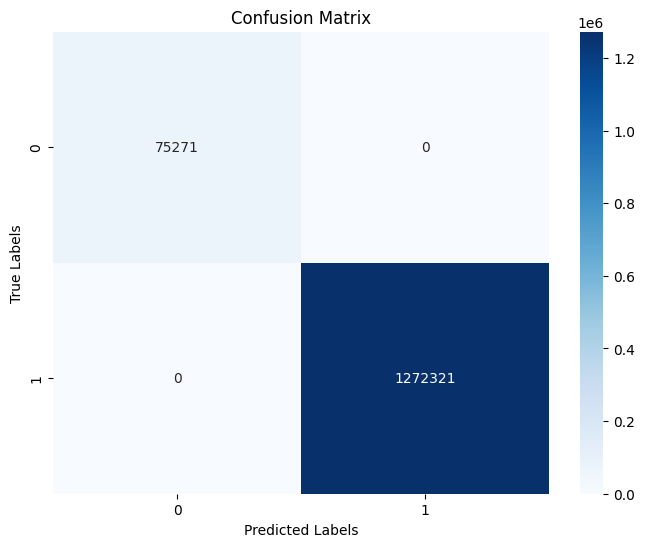

In [16]:

y3_pred = G_bin_3.predict(X3_test_r)  # Use the model you want (new_model or original model)

# Convert the predictions to class labels (if using softmax output)
y3_pred_labels = np.argmax(y3_pred, axis=1)

# Calculate the accuracy score
accuracy = accuracy_score(y3_test, y3_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y3_test, y3_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y3_test), yticklabels=np.unique(y3_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

In [5]:
updated_model32nd = load_model('D:/linthoi/FL_models/new/2ndbin_glob_model.h5')

In [19]:
updated_model3.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [20]:
updated_model3.fit(X3_train_r, y3_train, epochs=5, batch_size=32, validation_split=0.2 , callbacks=[early_stopping, checkpoint_callback])

Epoch 1/5
78602/78610 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9994 - loss: 0.0454
Epoch 1: val_loss did not improve from 0.02370
78610/78610 ━━━━━━━━━━━━━━━━━━━━ 444s 6ms/step - accuracy: 0.9994 - loss: 0.0454 - val_accuracy: 1.0000 - val_loss: 0.0339
Epoch 2/5
78606/78610 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0351
Epoch 2: val_loss did not improve from 0.02370
78610/78610 ━━━━━━━━━━━━━━━━━━━━ 415s 5ms/step - accuracy: 1.0000 - loss: 0.0351 - val_accuracy: 1.0000 - val_loss: 0.0312
Epoch 3/5
78602/78610 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0314
Epoch 3: val_loss did not improve from 0.02370
78610/78610 ━━━━━━━━━━━━━━━━━━━━ 412s 5ms/step - accuracy: 1.0000 - loss: 0.0314 - val_accuracy: 1.0000 - val_loss: 0.0276
Epoch 4/5
78609/78610 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 0.0292
Epoch 4: val_loss did not improve from 0.02370
78610/78610 ━━━━━━━━━━━━━━━━━━━━ 364s 5ms/step - accuracy: 1.0000 - loss: 0.0292 - val_

42113/42113 ━━━━━━━━━━━━━━━━━━━━ 54s 1ms/step
Accuracy Score: 0.9999992579356363


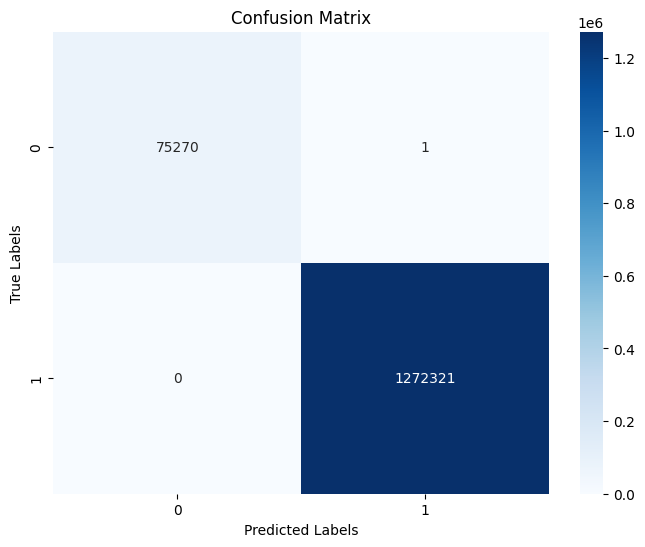

In [21]:

y3_pred = updated_model3.predict(X3_test_r)  # Use the model you want (new_model or original model)

# Convert the predictions to class labels (if using softmax output)
y3_pred_labels = np.argmax(y3_pred, axis=1)

# Calculate the accuracy score
accuracy = accuracy_score(y3_test, y3_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y3_test, y3_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y3_test), yticklabels=np.unique(y3_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

42113/42113 ━━━━━━━━━━━━━━━━━━━━ 43s 1ms/step
Accuracy Score: 0.94414407328034


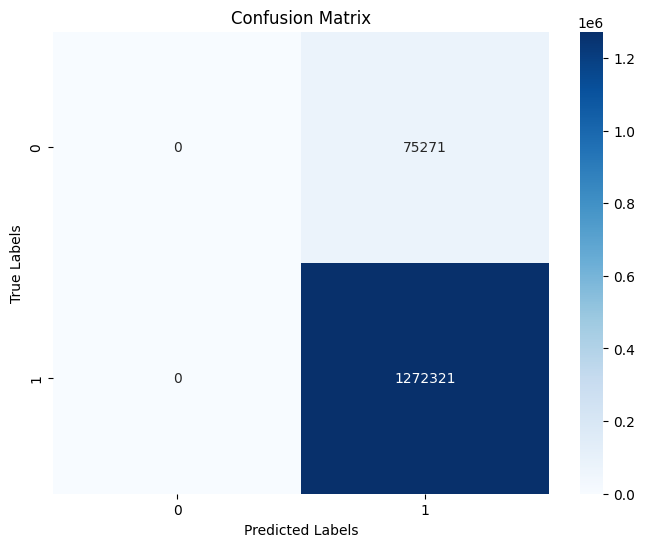

In [6]:

y3_pred = updated_model32nd.predict(X3_test_r)  # Use the model you want (new_model or original model)

# Convert the predictions to class labels (if using softmax output)
y3_pred_labels = np.argmax(y3_pred, axis=1)

# Calculate the accuracy score
accuracy = accuracy_score(y3_test, y3_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y3_test, y3_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y3_test), yticklabels=np.unique(y3_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

In [7]:
cl3['category'].unique()

array([1, 3, 6, 0], dtype=int64)

In [8]:
cl3['type'].unique()

array([11,  5, 10,  4,  0,  9], dtype=int64)

Multiclass classification for 4 class

In [ ]:
c3 = pd.read_csv(r"D:\linthoi\FL_splitted_data\iid_datas\c3.csv")
col_remove = ['SIP', 'DIP', 'SPort', 'DPort', 'SIT', 'STT']
c3=c3.drop(col_remove, axis=1, inplace=False)
irr_list = []
for i in c3:
    if len(c3[i].unique())<2:
        irr_list.append(i)
c3=c3.drop(irr_list, axis=1, inplace=False)


In [8]:
c3.to_csv(r"D:\linthoi\FL_splitted_data\iid_datas\c3.csv", index=False)

In [7]:
c3 = c3.dropna(axis=1)
c3

,FPT,LPT,FD,FAMin,FAMean,FAMax,FAStd,FIMean,FIMin,FIMax,...,HTTP_SCUL:,DNSQTL,DNS_QTUL,DNS_RCL,DNS_RCUL,MQTT_MTL,MQTT_MTUL,label,category,type
0,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,1,1,11
1,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,1,1,11
2,1.725543e+09,1.725543e+09,0.765041,0.765041,0.765041,0.765041,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,1,1,11
3,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,1,1,11
4,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,1,1,11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6264105,1.725543e+09,1.725543e+09,0.574569,0.574569,0.574569,0.574569,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,1,1,11
6264106,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,1,1,11
6264107,1.723123e+09,1.723123e+09,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,3,5
6264108,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,1,1,11


In [3]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()

In [4]:
cl3['label'] = label_encoder.fit_transform(cl3['label'])
category_mapping = pd.DataFrame({
    'label': label_encoder.classes_,
    'Encoded Value': label_encoder.transform(label_encoder.classes_)
})

# Display the result
print("Original label and Encoded Values:")
print(category_mapping)


cl3['category'] = label_encoder.fit_transform(cl3['category'])
category_mapping = pd.DataFrame({
    'category': label_encoder.classes_,
    'Encoded Value': label_encoder.transform(label_encoder.classes_)
})

# Display the result
print("Original Categories and Encoded Values:")
print(category_mapping)

cl3['type'] = label_encoder.fit_transform(cl3['type'])
category_mapping = pd.DataFrame({
    'type': label_encoder.classes_,
    'Encoded Value': label_encoder.transform(label_encoder.classes_)
})

# Display the result
print("Original Categories and Encoded Values:")
print(category_mapping)

Original label and Encoded Values:
    label  Encoded Value
0  Normal              0
1  attack              1
Original Categories and Encoded Values:
  category  Encoded Value
0     DDOS              0
1      DoS              1
2   Normal              2
3    Sybil              3
Original Categories and Encoded Values:
            type  Encoded Value
0     AMQP_flood              0
1         Normal              1
2        Slowite              2
3          Sybil              3
4  TCP_SYN_flood              4


In [7]:
cl3

,FPT,LPT,FD,FAMin,FAMean,FAMax,FAStd,FIMean,FIMin,FIMax,...,HTTP_SCUL:,DNSQTL,DNS_QTUL,DNS_RCL,DNS_RCUL,MQTT_MTL,MQTT_MTUL,label,category,type
0,1.723121e+09,1.723121e+09,0.048071,0.048071,0.048071,0.048071,0.000000,0.000000,0.000000,0.000000,...,0,0,0,0,0,0,0,0,2,1
1,1.723111e+09,1.723111e+09,0.011017,0.000012,0.002203,0.007158,0.002693,0.000560,-0.004201,0.007146,...,0,0,0,0,0,0,0,0,2,1
2,1.725543e+09,1.725543e+09,0.751403,0.751403,0.751403,0.751403,0.000000,0.000000,0.000000,0.000000,...,0,0,0,0,0,0,0,1,1,4
3,1.723109e+09,1.723109e+09,0.000026,0.000005,0.000013,0.000021,0.000008,0.000016,0.000016,0.000016,...,0,0,0,0,0,0,0,0,2,1
4,1.725787e+09,1.725787e+09,0.000001,0.000001,0.000001,0.000001,0.000000,0.000000,0.000000,0.000000,...,0,2,1,0,0,0,0,1,3,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2617845,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0,0,0,0,0,0,0,1,1,4
2617846,1.725543e+09,1.725543e+09,0.825828,0.825828,0.825828,0.825828,0.000000,0.000000,0.000000,0.000000,...,0,0,0,0,0,0,0,1,1,4
2617847,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0,0,0,0,0,0,0,1,1,4
2617848,1.723021e+09,1.723021e+09,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0,0,0,1,1,0,0,0,2,1


In [5]:
X1=cl3.iloc[:, :-3]
y1 = cl3.iloc[:, -1]
X1 = scaler.fit_transform(X1)
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.3, random_state=42)
#X1_train_r = X1_train.reshape((X1_train.shape[0], 1 , X1_train.shape[1]))
#X1_test_r = X1_test.reshape((X1_test.shape[0], 1 ,X1_test.shape[1]))

In [6]:
y1.value_counts()

type
1    1002791
4     879234
3     443440
0     231230
2      61155
Name: count, dtype: int64

In [8]:
cl3['category'].unique()

array([2, 1, 3, 0])

In [ ]:
from keras.models import load_model
model_cate = load_model('D:/linthoi/FL_models/new/Cate_glob_model.h5')
model_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
from tensorflow.keras.callbacks import ModelCheckpoint
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3_cate_best_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)

In [ ]:

early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3_cate_best_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)

In [10]:
model_cate.fit(X1_train_r, y1_train, epochs=10, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])

Epoch 1/10
45812/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9204 - loss: 0.5333
Epoch 1: val_loss improved from inf to 0.40721, saving model to D:/linthoi/FL_models/new/client3_cate_best_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 166s 3ms/step - accuracy: 0.9204 - loss: 0.5333 - val_accuracy: 0.9565 - val_loss: 0.4072
Epoch 2/10
45802/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9553 - loss: 0.4224
Epoch 2: val_loss improved from 0.40721 to 0.36677, saving model to D:/linthoi/FL_models/new/client3_cate_best_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 128s 3ms/step - accuracy: 0.9553 - loss: 0.4224 - val_accuracy: 0.9647 - val_loss: 0.3668
Epoch 3/10
45801/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9626 - loss: 0.3800
Epoch 3: val_loss improved from 0.36677 to 0.31644, saving model to D:/linthoi/FL_models/new/client3_cate_best_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 131s 3ms/step - accuracy: 0.9626 - loss: 0.3800 - val_accuracy: 0.9912 - val_loss: 

24543/24543 ━━━━━━━━━━━━━━━━━━━━ 30s 1ms/step
Accuracy Score: 0.9957968052664082


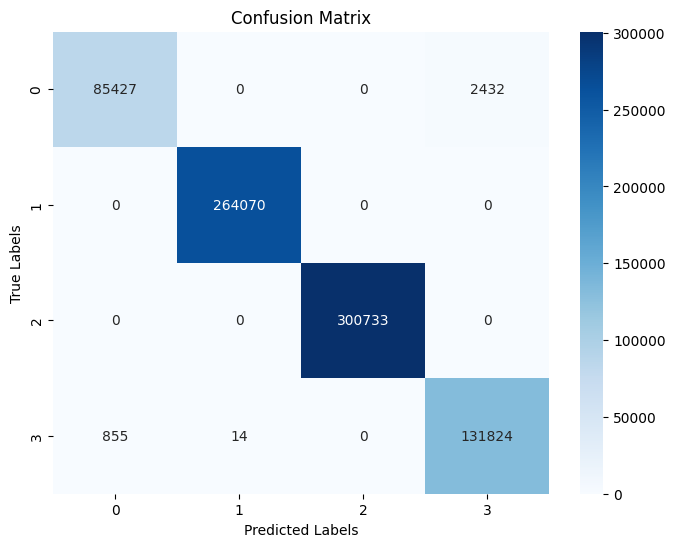

In [ ]:
y1_pred = model_cate.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

# Print the results
print(f"Accuracy for 4 class classification before fl: {accuracy:.4f}")
print(f"Precision for 4 class classification before fl: {precision:.4f}")
print(f"Recall for 4 class classification before fl: {recall:.4f}")
print(f"F1 Score for 4 class classification before fl: {f1:.4f}")
print(f"MCC for 4 class classification before fl: {mcc:.4f}")

In [12]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

# Print the results
print(f"Accuracy for 4 class classification before fl: {accuracy:.4f}")
print(f"Precision for 4 class classification before fl: {precision:.4f}")
print(f"Recall for 4 class classification before fl: {recall:.4f}")
print(f"F1 Score for 4 class classification before fl: {f1:.4f}")
print(f"MCC for 4 class classification before fl: {mcc:.4f}")

Accuracy for 4 class classification before fl: 0.9958
Precision for 4 class classification before fl: 0.9930
Recall for 4 class classification before fl: 0.9914
F1 Score for 4 class classification before fl: 0.9922
MCC for 4 class classification before fl: 0.9940


1st round fl for 4 class classification

In [9]:
from keras.models import load_model
model_cate = load_model('D:/linthoi/FL_models/new/1st_round_cate_glob_model.h5')
model_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
from tensorflow.keras.callbacks import ModelCheckpoint
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3_cate_after_1stround_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)

In [10]:
model_cate.fit(X1_train_r, y1_train, epochs=10, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])

Epoch 1/10
45808/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9666 - loss: 0.2942
Epoch 1: val_loss improved from inf to 0.21213, saving model to D:/linthoi/FL_models/new/client3_cate_after_1stround_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 142s 3ms/step - accuracy: 0.9666 - loss: 0.2942 - val_accuracy: 0.9851 - val_loss: 0.2121
Epoch 2/10
45810/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9881 - loss: 0.2395
Epoch 2: val_loss improved from 0.21213 to 0.20472, saving model to D:/linthoi/FL_models/new/client3_cate_after_1stround_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 142s 3ms/step - accuracy: 0.9881 - loss: 0.2395 - val_accuracy: 0.9985 - val_loss: 0.2047
Epoch 3/10
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9890 - loss: 0.2324
Epoch 3: val_loss improved from 0.20472 to 0.19601, saving model to D:/linthoi/FL_models/new/client3_cate_after_1stround_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 145s 3ms/step - accuracy: 0.9890 - loss: 0.2324 - val

24543/24543 ━━━━━━━━━━━━━━━━━━━━ 30s 1ms/step
Accuracy Score: 0.9991774420485003


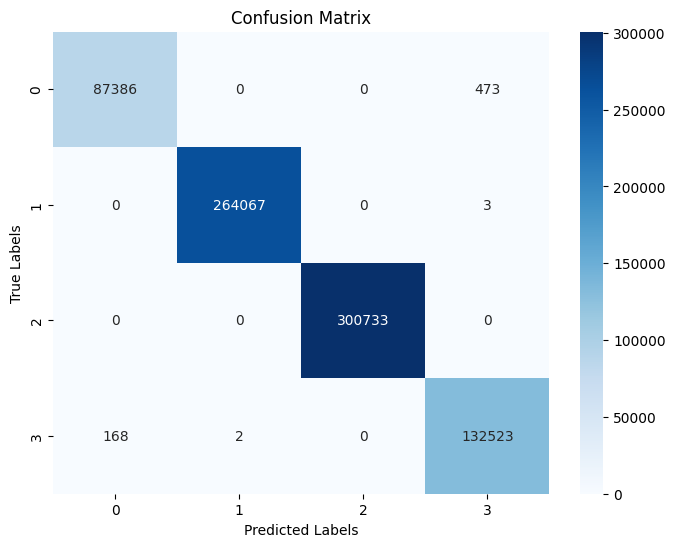

Accuracy for 4 class classification 1st round fl: 0.9992
Precision for 4 class classification 1st round fl: 0.9986
Recall for 4 class classification 1st round fl: 0.9983
F1 Score for 4 class classification 1st round fl: 0.9985
MCC for 4 class classification 1st round fl: 0.9988


In [12]:
y1_pred = model_cate.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

# Print the results
print(f"Accuracy for 4 class classification 1st round fl: {accuracy:.4f}")
print(f"Precision for 4 class classification 1st round fl: {precision:.4f}")
print(f"Recall for 4 class classification 1st round fl: {recall:.4f}")
print(f"F1 Score for 4 class classification 1st round fl: {f1:.4f}")
print(f"MCC for 4 class classification 1st round fl: {mcc:.4f}")

2nd fl round for 4 class classification

In [13]:
model_cate = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/updated_models/2nd_round_cate_glob_model.h5')
model_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/category/client3_cate_2ndround_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
model_cate.fit(X1_train_r, y1_train, epochs=10, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])

Epoch 1/10
45807/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9822 - loss: 0.2111
Epoch 1: val_loss improved from inf to 0.15819, saving model to D:/linthoi/FL_models/new/client3/category/client3_cate_2ndround_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 139s 3ms/step - accuracy: 0.9822 - loss: 0.2111 - val_accuracy: 0.9993 - val_loss: 0.1582
Epoch 2/10
45807/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9921 - loss: 0.1921
Epoch 2: val_loss did not improve from 0.15819
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 145s 3ms/step - accuracy: 0.9921 - loss: 0.1921 - val_accuracy: 0.9997 - val_loss: 0.1610
Epoch 3/10
45803/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9923 - loss: 0.1901
Epoch 3: val_loss improved from 0.15819 to 0.15693, saving model to D:/linthoi/FL_models/new/client3/category/client3_cate_2ndround_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 137s 3ms/step - accuracy: 0.9923 - loss: 0.1901 - val_accuracy: 0.9989 - val_loss: 0.1569
Epoch 4/10
45806/45813 ━━━━━

24543/24543 ━━━━━━━━━━━━━━━━━━━━ 30s 1ms/step
Accuracy Score: 0.9997848106907068


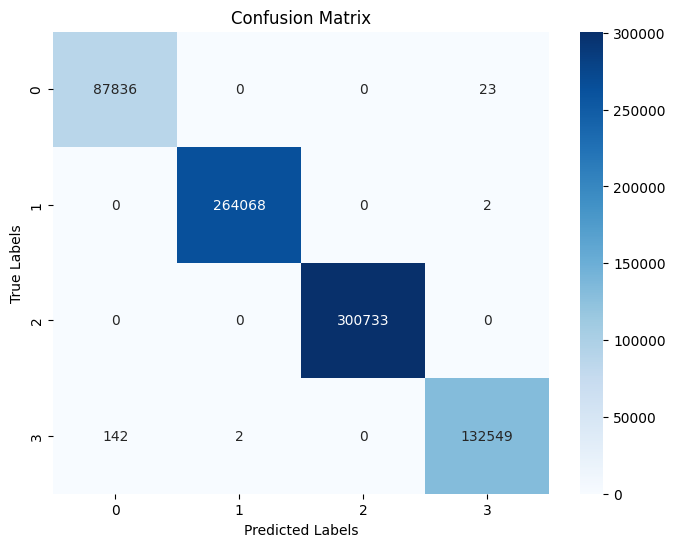

Accuracy for 4 class classification 2nd round fl: 0.9998
Precision for 4 class classification 2nd round fl: 0.9995
Recall for 4 class classification 2nd round fl: 0.9997
F1 Score for 4 class classification 2nd round fl: 0.9996
MCC for 4 class classification 2nd round fl: 0.9997


In [14]:
y1_pred = model_cate.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

# Print the results
print(f"Accuracy for 4 class classification 2nd round fl: {accuracy:.4f}")
print(f"Precision for 4 class classification 2nd round fl: {precision:.4f}")
print(f"Recall for 4 class classification 2nd round fl: {recall:.4f}")
print(f"F1 Score for 4 class classification 2nd round fl: {f1:.4f}")
print(f"MCC for 4 class classification 2nd round fl: {mcc:.4f}")

3rd fl round categorical classification

In [11]:
model_cate = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/updated_models/3rd_round_cate_glob_model.h5')
model_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/category/client3_cate_3rdround_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
model_cate.fit(X1_train_r, y1_train, epochs=10, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])

Epoch 1/10
45810/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9886 - loss: 0.1784
Epoch 1: val_loss improved from inf to 0.13782, saving model to D:/linthoi/FL_models/new/client3/category/client3_cate_3rdround_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 127s 3ms/step - accuracy: 0.9886 - loss: 0.1784 - val_accuracy: 0.9993 - val_loss: 0.1378
Epoch 2/10
45795/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9934 - loss: 0.1710
Epoch 2: val_loss improved from 0.13782 to 0.13698, saving model to D:/linthoi/FL_models/new/client3/category/client3_cate_3rdround_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 123s 3ms/step - accuracy: 0.9934 - loss: 0.1710 - val_accuracy: 0.9998 - val_loss: 0.1370
Epoch 3/10
45799/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9933 - loss: 0.1708
Epoch 3: val_loss did not improve from 0.13698
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 135s 3ms/step - accuracy: 0.9933 - loss: 0.1708 - val_accuracy: 0.9998 - val_loss: 0.1373
Epoch 4/10
45804/45813 ━━━━━

24543/24543 ━━━━━━━━━━━━━━━━━━━━ 27s 1ms/step
Accuracy Score: 0.9998281032144699


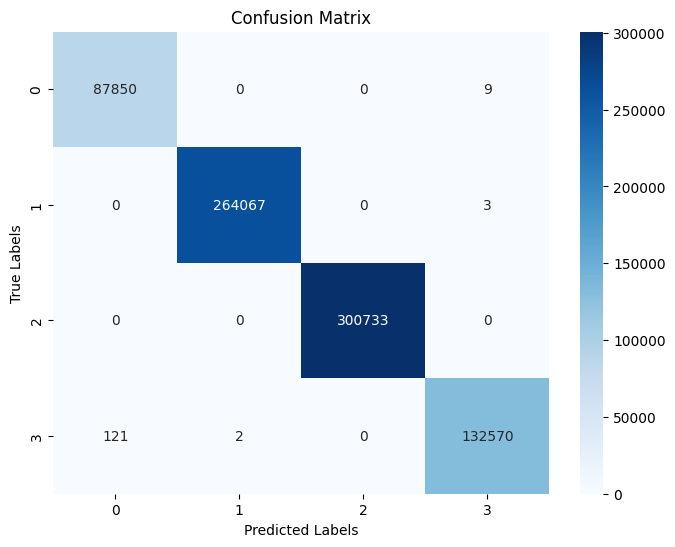

Accuracy for 4 class classification 3rd round fl: 0.9998
Precision for 4 class classification 3rd round fl: 0.9996
Recall for 4 class classification 3rd round fl: 0.9997
F1 Score for 4 class classification 3rd round fl: 0.9997
MCC for 4 class classification 3rd round fl: 0.9998


In [12]:
y1_pred = model_cate.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

# Print the results
print(f"Accuracy for 4 class classification 3rd round fl: {accuracy:.4f}")
print(f"Precision for 4 class classification 3rd round fl: {precision:.4f}")
print(f"Recall for 4 class classification 3rd round fl: {recall:.4f}")
print(f"F1 Score for 4 class classification 3rd round fl: {f1:.4f}")
print(f"MCC for 4 class classification 3rd round fl: {mcc:.4f}")

5 class multiclass classification (type) before fl

In [7]:
from keras.models import load_model
model_type = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/firstinitialized/Type_glob_model.h5')
model_type.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
from tensorflow.keras.callbacks import ModelCheckpoint
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/type/client3_type_bforeFL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
model_type.fit(X1_train_r, y1_train, epochs=10, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])

Epoch 1/10
45799/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9035 - loss: 0.6154
Epoch 1: val_loss improved from inf to 0.46543, saving model to D:/linthoi/FL_models/new/client3/type/client3_type_bforeFL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 135s 3ms/step - accuracy: 0.9035 - loss: 0.6154 - val_accuracy: 0.9509 - val_loss: 0.4654
Epoch 2/10
45810/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9442 - loss: 0.4868
Epoch 2: val_loss improved from 0.46543 to 0.43560, saving model to D:/linthoi/FL_models/new/client3/type/client3_type_bforeFL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 143s 3ms/step - accuracy: 0.9442 - loss: 0.4868 - val_accuracy: 0.9536 - val_loss: 0.4356
Epoch 3/10
45799/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9472 - loss: 0.4563
Epoch 3: val_loss improved from 0.43560 to 0.38680, saving model to D:/linthoi/FL_models/new/client3/type/client3_type_bforeFL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 160s 3ms/step - accuracy: 0.9472 - 

24543/24543 ━━━━━━━━━━━━━━━━━━━━ 36s 1ms/step
Accuracy Score: 0.9699384354845898


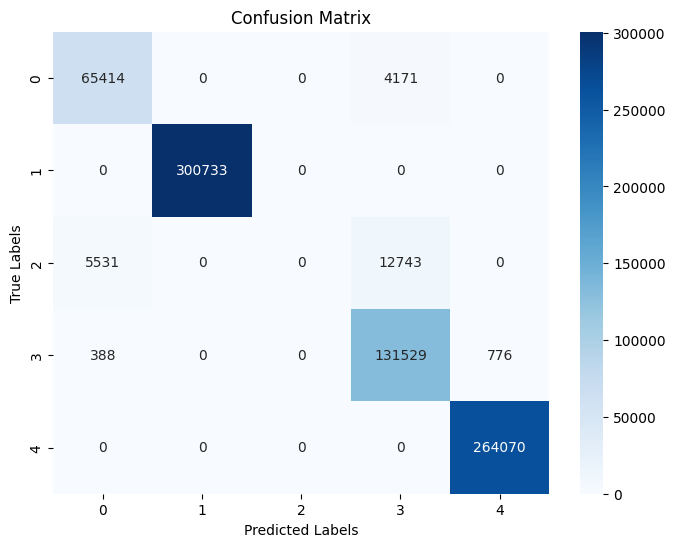

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Accuracy for 4 class classification bfore fl: 0.9699
Precision for 4 class classification bfore fl: 0.7600
Recall for 4 class classification bfore fl: 0.7863
F1 Score for 4 class classification bfore fl: 0.7725
MCC for 4 class classification bfore fl: 0.9577


In [ ]:
y1_pred = model_type.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

# Print the results
print(f"Accuracy for 5 class classification bfore fl: {accuracy:.4f}")
print(f"Precision for 5 class classification bfore fl: {precision:.4f}")
print(f"Recall for 5 class classification bfore fl: {recall:.4f}")
print(f"F1 Score for 5 class classification bfore fl: {f1:.4f}")
print(f"MCC for 5 class classification bfore fl: {mcc:.4f}")

5 class multiclass classification 1st FL round (type)

In [9]:
model_type1 = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/1st_round_type_glob_model.h5')
model_type1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
from tensorflow.keras.callbacks import ModelCheckpoint
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/type/client3_type_1st_round_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
model_type1.fit(X1_train_r, y1_train, epochs=10, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])

Epoch 1/10
45800/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9468 - loss: 0.4074
Epoch 1: val_loss improved from inf to 0.29257, saving model to D:/linthoi/FL_models/new/client3/type/client3_type_1st_round_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 130s 3ms/step - accuracy: 0.9468 - loss: 0.4073 - val_accuracy: 0.9736 - val_loss: 0.2926
Epoch 2/10
45797/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9664 - loss: 0.3261
Epoch 2: val_loss improved from 0.29257 to 0.27771, saving model to D:/linthoi/FL_models/new/client3/type/client3_type_1st_round_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 137s 3ms/step - accuracy: 0.9664 - loss: 0.3261 - val_accuracy: 0.9726 - val_loss: 0.2777
Epoch 3/10
45803/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9674 - loss: 0.3112
Epoch 3: val_loss improved from 0.27771 to 0.27128, saving model to D:/linthoi/FL_models/new/client3/type/client3_type_1st_round_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 142s 3ms/step - accu

24543/24543 ━━━━━━━━━━━━━━━━━━━━ 30s 1ms/step
Accuracy Score: 0.9756135760261283


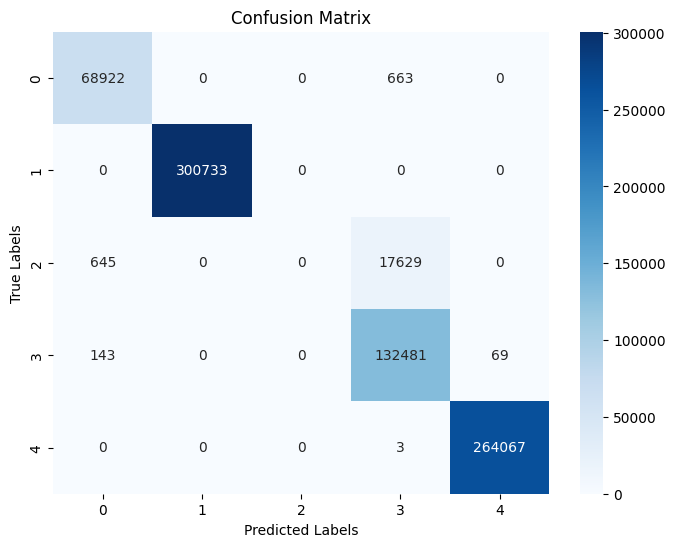

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Accuracy for 5 class classification 1st_round fl: 0.9756
Precision for 5 class classification 1st_round fl: 0.7734
Recall for 5 class classification 1st_round fl: 0.7978
F1 Score for 5 class classification 1st_round fl: 0.7848
MCC for 5 class classification 1st_round fl: 0.9659


In [10]:
y1_pred = model_type1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

# Print the results
print(f"Accuracy for 5 class classification 1st_round fl: {accuracy:.4f}")
print(f"Precision for 5 class classification 1st_round fl: {precision:.4f}")
print(f"Recall for 5 class classification 1st_round fl: {recall:.4f}")
print(f"F1 Score for 5 class classification 1st_round fl: {f1:.4f}")
print(f"MCC for 5 class classification 1st_round fl: {mcc:.4f}")

2nd fl round 5 class multiclass classification round

Epoch 1/10
45807/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9609 - loss: 0.3193
Epoch 1: val_loss improved from inf to 0.25145, saving model to D:/linthoi/FL_models/new/client3/type/client3_type_2nd_round_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 131s 3ms/step - accuracy: 0.9609 - loss: 0.3193 - val_accuracy: 0.9731 - val_loss: 0.2515
Epoch 2/10
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9687 - loss: 0.2846
Epoch 2: val_loss improved from 0.25145 to 0.24129, saving model to D:/linthoi/FL_models/new/client3/type/client3_type_2nd_round_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 150s 3ms/step - accuracy: 0.9687 - loss: 0.2846 - val_accuracy: 0.9760 - val_loss: 0.2413
Epoch 3/10
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9688 - loss: 0.2794
Epoch 3: val_loss did not improve from 0.24129
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 157s 3ms/step - accuracy: 0.9688 - loss: 0.2794 - val_accuracy: 0.9733 - val_loss: 0.2439
Epoch 4/10
45799/45813 ━━━━━

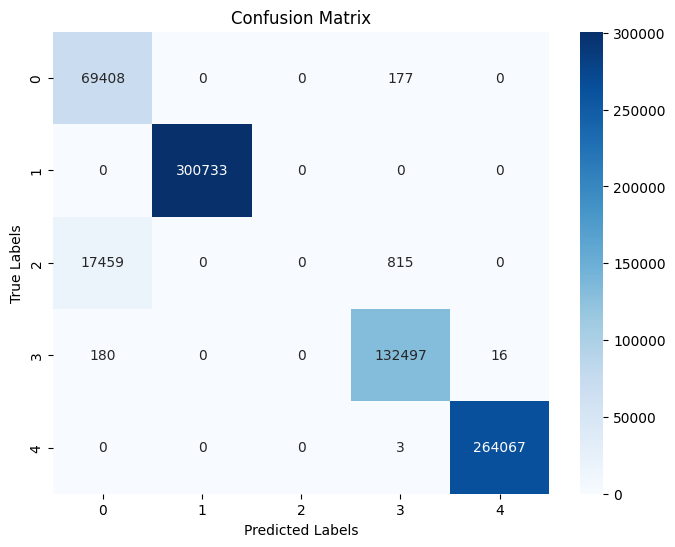

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [6]:
model_type1 = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/2nd_round_type_glob_model.h5')
model_type1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
from tensorflow.keras.callbacks import ModelCheckpoint
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/type/client3_type_2nd_round_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
model_type1.fit(X1_train_r, y1_train, epochs=10, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])
y1_pred = model_type1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

# Print the results


In [7]:
print(f"Accuracy for 5 class classification 2nd_round fl: {accuracy:.4f}")
print(f"Precision for 5 class classification 2nd_round fl: {precision:.4f}")
print(f"Recall for 5 class classification 2nd_round fl: {recall:.4f}")
print(f"F1 Score for 5 class classification 2nd_round fl: {f1:.4f}")
print(f"MCC for 5 class classification 2nd_round fl: {mcc:.4f}")

Accuracy for 5 class classification 2nd_round fl: 0.9763
Precision for 5 class classification 2nd_round fl: 0.7580
Recall for 5 class classification 2nd_round fl: 0.7992
F1 Score for 5 class classification 2nd_round fl: 0.7763
MCC for 5 class classification 2nd_round fl: 0.9669


3rd round (type)

Epoch 1/5
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9646 - loss: 0.2656
Epoch 1: val_loss improved from inf to 0.20383, saving model to D:/linthoi/FL_models/new/client3/type/client3_type_3rd_round_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 191s 4ms/step - accuracy: 0.9646 - loss: 0.2656 - val_accuracy: 0.9758 - val_loss: 0.2038
Epoch 2/5
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9696 - loss: 0.2468
Epoch 2: val_loss improved from 0.20383 to 0.20190, saving model to D:/linthoi/FL_models/new/client3/type/client3_type_3rd_round_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 178s 4ms/step - accuracy: 0.9696 - loss: 0.2468 - val_accuracy: 0.9761 - val_loss: 0.2019
Epoch 3/5
45811/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9698 - loss: 0.2450
Epoch 3: val_loss did not improve from 0.20190
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 163s 4ms/step - accuracy: 0.9698 - loss: 0.2450 - val_accuracy: 0.9761 - val_loss: 0.2042
Epoch 4/5
45798/45813 ━━━━━━━━━

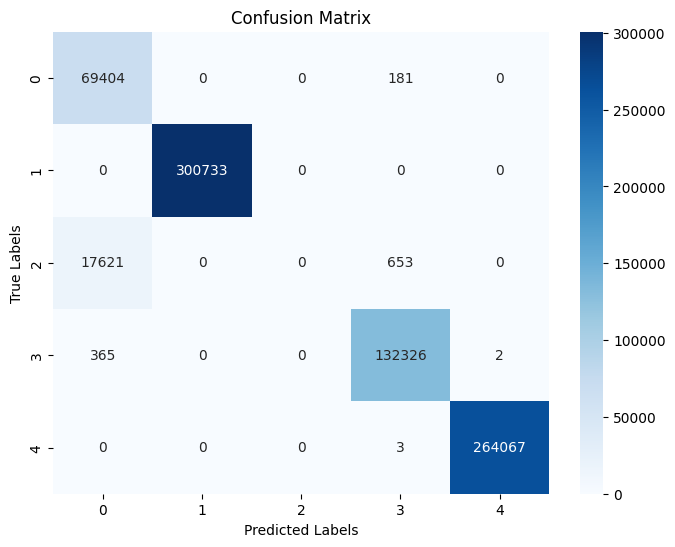

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [8]:
model_type1 = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/3rd_round_type_glob_model.h5')
model_type1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
from tensorflow.keras.callbacks import ModelCheckpoint
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/type/client3_type_3rd_round_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
model_type1.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])
y1_pred = model_type1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

# Print the results


In [9]:
print(f"Accuracy for 5 class classification 3rd_round fl: {accuracy:.4f}")
print(f"Precision for 5 class classification 3rd_round fl: {precision:.4f}")
print(f"Recall for 5 class classification 3rd_round fl: {recall:.4f}")
print(f"F1 Score for 5 class classification 3rd_round fl: {f1:.4f}")
print(f"MCC for 5 class classification 3rd_round fl: {mcc:.4f}")

Accuracy for 5 class classification 3rd_round fl: 0.9760
Precision for 5 class classification 3rd_round fl: 0.7576
Recall for 5 class classification 3rd_round fl: 0.7989
F1 Score for 5 class classification 3rd_round fl: 0.7759
MCC for 5 class classification 3rd_round fl: 0.9666


CNN_GRU MDPI before FL


In [6]:
cnn_gru_mdpi = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/firstinitialized/CNN_GRU_MDPI_Type_glob_model.h5')
cnn_gru_mdpi.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

Epoch 1/5
45812/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9898 - loss: 0.0332
Epoch 1: val_loss improved from inf to 0.00387, saving model to D:/linthoi/FL_models/new/client3/type/client3_cnn_gru_mdpi_type_bfore_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 191s 4ms/step - accuracy: 0.9898 - loss: 0.0332 - val_accuracy: 0.9988 - val_loss: 0.0039
Epoch 2/5
45807/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9981 - loss: 0.0065
Epoch 2: val_loss did not improve from 0.00387
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 163s 4ms/step - accuracy: 0.9981 - loss: 0.0065 - val_accuracy: 0.9980 - val_loss: 0.0186
Epoch 3/5
45807/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9984 - loss: 0.0056
Epoch 3: val_loss did not improve from 0.00387
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 166s 4ms/step - accuracy: 0.9984 - loss: 0.0056 - val_accuracy: 0.9935 - val_loss: 0.0481
Epoch 4/5
45798/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9985 - loss: 0.0050
Epoch 4: val_loss improved from

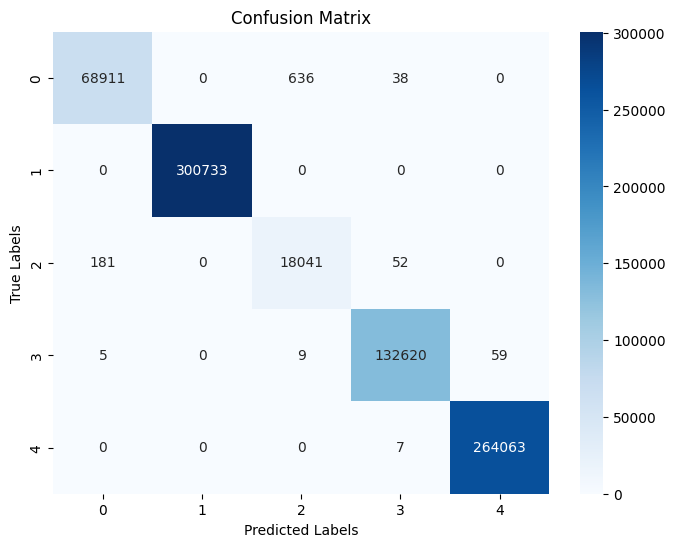

In [7]:
#cnn_gru_mdpi.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2)
from tensorflow.keras.callbacks import ModelCheckpoint
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/type/client3_cnn_gru_mdpi_type_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
cnn_gru_mdpi.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = cnn_gru_mdpi.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [8]:
print(f"Accuracy for 5 class classification cnn_gru_mdpi_bfore fl: {accuracy:.4f}")
print(f"Precision for 5 class classification cnn_gru_mdpi_bfore fl: {precision:.4f}")
print(f"Recall for 5 class classification cnn_gru_mdpi_bfore fl: {recall:.4f}")
print(f"F1 Score for 5 class classification cnn_gru_mdpi_bfore fl: {f1:.4f}")
print(f"MCC for 5 class classification cnn_gru_mdpi_bfore fl: {mcc:.4f}")

Accuracy for 5 class classification cnn_gru_mdpi_bfore fl: 0.9987
Precision for 5 class classification cnn_gru_mdpi_bfore fl: 0.9924
Recall for 5 class classification cnn_gru_mdpi_bfore fl: 0.9954
F1 Score for 5 class classification cnn_gru_mdpi_bfore fl: 0.9939
MCC for 5 class classification cnn_gru_mdpi_bfore fl: 0.9982


1st round cnn_gru_mdpi_type

Epoch 1/5
45807/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9935 - loss: 0.0378
Epoch 1: val_loss improved from inf to 0.00483, saving model to D:/linthoi/FL_models/new/client3/type/client3_cnn_gru_mdpi_type_1stround_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 131s 3ms/step - accuracy: 0.9935 - loss: 0.0378 - val_accuracy: 0.9989 - val_loss: 0.0048
Epoch 2/5
45808/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9986 - loss: 0.0048
Epoch 2: val_loss improved from 0.00483 to 0.00310, saving model to D:/linthoi/FL_models/new/client3/type/client3_cnn_gru_mdpi_type_1stround_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 162s 4ms/step - accuracy: 0.9986 - loss: 0.0048 - val_accuracy: 0.9990 - val_loss: 0.0031
Epoch 3/5
45810/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9988 - loss: 0.0044
Epoch 3: val_loss did not improve from 0.00310
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 178s 4ms/step - accuracy: 0.9988 - loss: 0.0044 - val_accuracy: 0.9988 - val_loss: 0.0038
Epoch 4

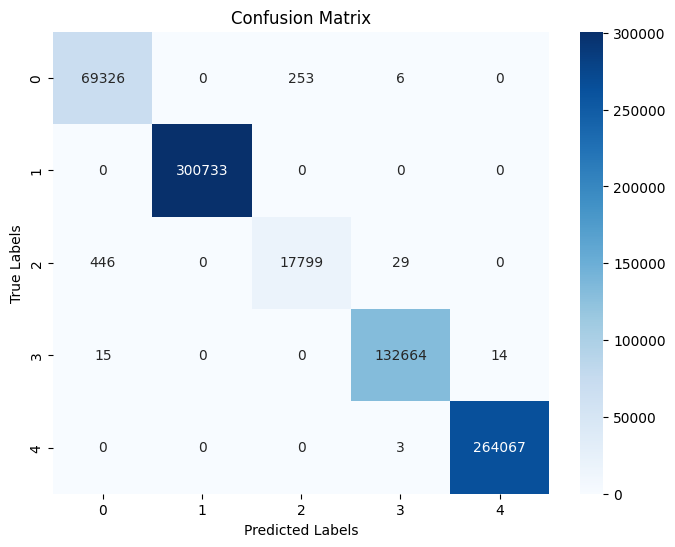

In [8]:

early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)

cnn_gru_mdpi1 = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/1st_round_CNN_GRU_MDPI_Type_model.h5')
cnn_gru_mdpi1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/type/client3_cnn_gru_mdpi_type_1stround_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
cnn_gru_mdpi1.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = cnn_gru_mdpi1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [9]:
print(f"Accuracy for 5 class classification cnn_gru_mdpi_1stround fl: {accuracy:.4f}")
print(f"Precision for 5 class classification cnn_gru_mdpi_1stround fl: {precision:.4f}")
print(f"Recall for 5 class classification cnn_gru_mdpi_1stround fl: {recall:.4f}")
print(f"F1 Score for 5 class classification cnn_gru_mdpi_1stround fl: {f1:.4f}")
print(f"MCC for 5 class classification cnn_gru_mdpi_1stround fl: {mcc:.4f}")

Accuracy for 5 class classification cnn_gru_mdpi_1stround fl: 0.9990
Precision for 5 class classification cnn_gru_mdpi_1stround fl: 0.9958
Recall for 5 class classification cnn_gru_mdpi_1stround fl: 0.9940
F1 Score for 5 class classification cnn_gru_mdpi_1stround fl: 0.9949
MCC for 5 class classification cnn_gru_mdpi_1stround fl: 0.9986


2nd fl round cnn_gru model (type)

Epoch 1/5
45804/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9929 - loss: 0.0432
Epoch 1: val_loss improved from inf to 0.00333, saving model to D:/linthoi/FL_models/new/client3/type/client3_cnn_gru_mdpi_type_2ndround_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 130s 3ms/step - accuracy: 0.9929 - loss: 0.0432 - val_accuracy: 0.9990 - val_loss: 0.0033
Epoch 2/5
45810/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9987 - loss: 0.0047
Epoch 2: val_loss improved from 0.00333 to 0.00308, saving model to D:/linthoi/FL_models/new/client3/type/client3_cnn_gru_mdpi_type_2ndround_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 143s 3ms/step - accuracy: 0.9987 - loss: 0.0047 - val_accuracy: 0.9991 - val_loss: 0.0031
Epoch 3/5
45807/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9988 - loss: 0.0041
Epoch 3: val_loss improved from 0.00308 to 0.00307, saving model to D:/linthoi/FL_models/new/client3/type/client3_cnn_gru_mdpi_type_2ndround_FL_weight.keras
45813/45813 ━━━━━━━━

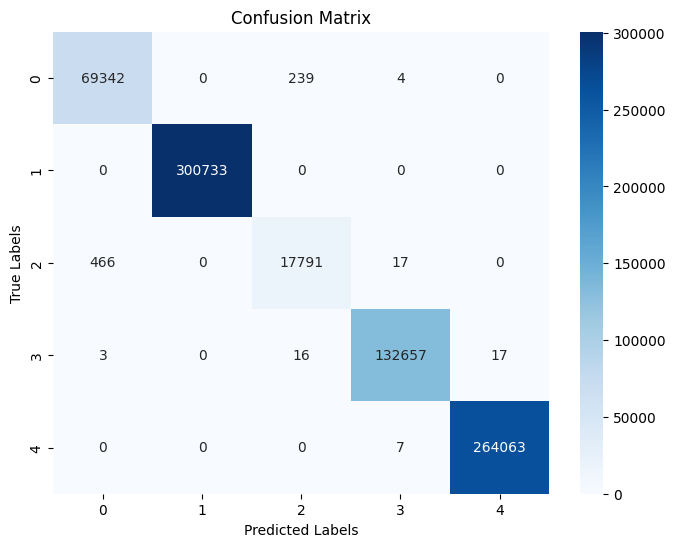

In [6]:

early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)

cnn_gru_mdpi1 = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/2nd_round_CNN_GRU_MDPI_Type_model.h5')
cnn_gru_mdpi1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/type/client3_cnn_gru_mdpi_type_2ndround_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
cnn_gru_mdpi1.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = cnn_gru_mdpi1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [7]:
print(f"Accuracy for 5 class classification cnn_gru_mdpi_2ndround fl: {accuracy:.4f}")
print(f"Precision for 5 class classification cnn_gru_mdpi_2ndround fl: {precision:.4f}")
print(f"Recall for 5 class classification cnn_gru_mdpi_2ndround fl: {recall:.4f}")
print(f"F1 Score for 5 class classification cnn_gru_mdpi_2ndround fl: {f1:.4f}")
print(f"MCC for 5 class classification cnn_gru_mdpi_2ndround fl: {mcc:.4f}")

Accuracy for 5 class classification cnn_gru_mdpi_2ndround fl: 0.9990
Precision for 5 class classification cnn_gru_mdpi_2ndround fl: 0.9958
Recall for 5 class classification cnn_gru_mdpi_2ndround fl: 0.9940
F1 Score for 5 class classification cnn_gru_mdpi_2ndround fl: 0.9949
MCC for 5 class classification cnn_gru_mdpi_2ndround fl: 0.9986


3rd fl round cnn_gru_mdpi (type)

Epoch 1/5
45806/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9944 - loss: 0.0250
Epoch 1: val_loss improved from inf to 0.00416, saving model to D:/linthoi/FL_models/new/client3/type/client3_cnn_gru_mdpi_type_3rdround_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 182s 4ms/step - accuracy: 0.9944 - loss: 0.0250 - val_accuracy: 0.9989 - val_loss: 0.0042
Epoch 2/5
45804/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9988 - loss: 0.0045
Epoch 2: val_loss improved from 0.00416 to 0.00282, saving model to D:/linthoi/FL_models/new/client3/type/client3_cnn_gru_mdpi_type_3rdround_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 170s 4ms/step - accuracy: 0.9988 - loss: 0.0045 - val_accuracy: 0.9991 - val_loss: 0.0028
Epoch 3/5
45808/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9988 - loss: 0.0042
Epoch 3: val_loss did not improve from 0.00282
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 161s 4ms/step - accuracy: 0.9988 - loss: 0.0042 - val_accuracy: 0.9993 - val_loss: 0.0029
Epoch 4

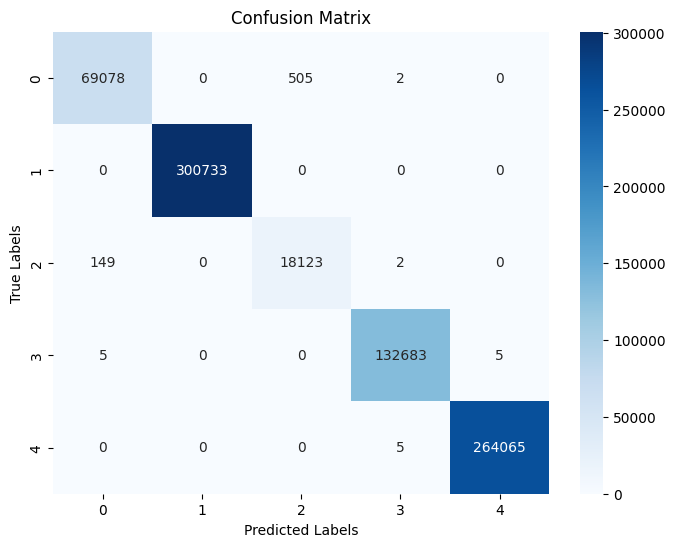

In [8]:

early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)

cnn_gru_mdpi1 = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/3rd_round_CNN_GRU_MDPI_Type_model.h5')
cnn_gru_mdpi1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/type/client3_cnn_gru_mdpi_type_3rdround_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
cnn_gru_mdpi1.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = cnn_gru_mdpi1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [9]:
print(f"Accuracy for 5 class classification cnn_gru_mdpi_3rdround fl: {accuracy:.4f}")
print(f"Precision for 5 class classification cnn_gru_mdpi_3rdround fl: {precision:.4f}")
print(f"Recall for 5 class classification cnn_gru_mdpi_3rdround fl: {recall:.4f}")
print(f"F1 Score for 5 class classification cnn_gru_mdpi_3rdround fl: {f1:.4f}")
print(f"MCC for 5 class classification cnn_gru_mdpi_3rdround fl: {mcc:.4f}")

Accuracy for 5 class classification cnn_gru_mdpi_3rdround fl: 0.9991
Precision for 5 class classification cnn_gru_mdpi_3rdround fl: 0.9941
Recall for 5 class classification cnn_gru_mdpi_3rdround fl: 0.9969
F1 Score for 5 class classification cnn_gru_mdpi_3rdround fl: 0.9955
MCC for 5 class classification cnn_gru_mdpi_3rdround fl: 0.9988


before fl cnn_gru_mdpi (binary)

In [3]:
X1=c3.iloc[:, :-3]
y1 = c3.iloc[:, -2]
X1 = scaler.fit_transform(X1)
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.3, random_state=42)
X1_train_r = X1_train.reshape((X1_train.shape[0], 1 , X1_train.shape[1]))
X1_test_r = X1_test.reshape((X1_test.shape[0], 1 ,X1_test.shape[1]))

ValueError: could not convert string to float: 'GET'

Epoch 1/5
83021/83022 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9996 - loss: 0.0014
Epoch 1: val_loss improved from inf to 0.00000, saving model to D:/linthoi/FL_models/new/client3/binary/client3_cnn_gru_mdpi_binary_beforeFL_weight_iid.keras
83022/83022 ━━━━━━━━━━━━━━━━━━━━ 394s 5ms/step - accuracy: 0.9996 - loss: 0.0014 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 2/5
83015/83022 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 1.8418e-12
Epoch 2: val_loss did not improve from 0.00000
83022/83022 ━━━━━━━━━━━━━━━━━━━━ 374s 5ms/step - accuracy: 1.0000 - loss: 1.8418e-12 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 3/5
83009/83022 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 1.8772e-13
Epoch 3: val_loss did not improve from 0.00000
83022/83022 ━━━━━━━━━━━━━━━━━━━━ 354s 4ms/step - accuracy: 1.0000 - loss: 1.8775e-13 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 4/5
83020/83022 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 4.

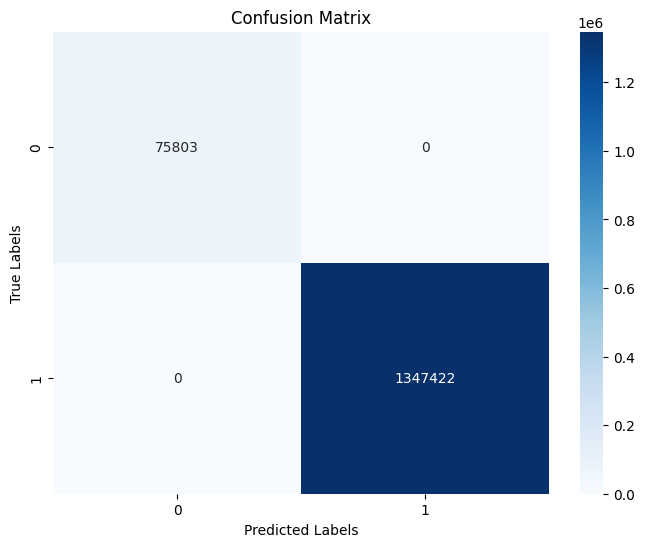

In [5]:

early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)

cnn_gru_mdpi1 = load_model('D:/linthoi/FL_models/new/glob_models/Binary_glob_model/firstinitialized/CNN_GRU_MDPI_binary_glob_model.h5')
cnn_gru_mdpi1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/binary/client3_cnn_gru_mdpi_binary_beforeFL_weight_iid.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
cnn_gru_mdpi1.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = cnn_gru_mdpi1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [6]:
print(f"Accuracy for 2 class classification cnn_gru_mdpi_bforefl: {accuracy:.4f}")
print(f"Precision for 2 class classification cnn_gru_mdpi_bforefl fl: {precision:.4f}")
print(f"Recall for 2 class classification cnn_gru_mdpi_bforefl fl: {recall:.4f}")
print(f"F1 Score for 2 class classification cnn_gru_mdpi_bforefl fl: {f1:.4f}")
print(f"MCC for 2 class classification cnn_gru_mdpi_bforefl fl: {mcc:.4f}")

Accuracy for 2 class classification cnn_gru_mdpi_bforefl: 1.0000
Precision for 2 class classification cnn_gru_mdpi_bforefl fl: 1.0000
Recall for 2 class classification cnn_gru_mdpi_bforefl fl: 1.0000
F1 Score for 2 class classification cnn_gru_mdpi_bforefl fl: 1.0000
MCC for 2 class classification cnn_gru_mdpi_bforefl fl: 1.0000


before fl round categorical classification cnn_gru_mdpi

In [6]:
c3

,FPT,LPT,FD,FAMin,FAMean,FAMax,FAStd,FIMean,FIMin,FIMax,...,DNS_QTM,DNS_RCL,DNS_RCUL,DNS_RCM,MQTT_MTL,MQTT_MTUL,MQTT_MTM,label,category,type
0,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,NaN,0,0,NaN,0,0,NaN,1,1,11
1,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,NaN,0,0,NaN,0,0,NaN,1,1,11
2,1.725543e+09,1.725543e+09,0.765041,0.765041,0.765041,0.765041,0.0,0.0,0.0,0.0,...,NaN,0,0,NaN,0,0,NaN,1,1,11
3,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,NaN,0,0,NaN,0,0,NaN,1,1,11
4,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,NaN,0,0,NaN,0,0,NaN,1,1,11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6264105,1.725543e+09,1.725543e+09,0.574569,0.574569,0.574569,0.574569,0.0,0.0,0.0,0.0,...,NaN,0,0,NaN,0,0,NaN,1,1,11
6264106,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,NaN,0,0,NaN,0,0,NaN,1,1,11
6264107,1.723123e+09,1.723123e+09,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,NaN,0,0,NaN,0,0,NaN,0,3,5
6264108,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,NaN,0,0,NaN,0,0,NaN,1,1,11


In [9]:
X1=c3.iloc[:, :-3]
y1 = c3.iloc[:, -2]
X1 = scaler.fit_transform(X1)
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.3, random_state=42)
X1_train_r = X1_train.reshape((X1_train.shape[0], 1 , X1_train.shape[1]))
X1_test_r = X1_test.reshape((X1_test.shape[0], 1 ,X1_test.shape[1]))

In [ ]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
cnn_gru_mdpi1 = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/updated_models/1stround_CNN_GRU_MDPI_cate_model.h5')
cnn_gru_mdpi1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/category/client3_cnn_gru_mdpi_cate_1stFL_weight_iid.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
cnn_gru_mdpi1.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = cnn_gru_mdpi1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


Epoch 1/5
83020/83022 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9976 - loss: 0.0122
Epoch 1: val_loss improved from inf to 0.00274, saving model to D:/linthoi/FL_models/new/client3/category/client3_cnn_gru_mdpi_cate_1stFL_weight_iid.keras
83022/83022 ━━━━━━━━━━━━━━━━━━━━ 284s 3ms/step - accuracy: 0.9976 - loss: 0.0122 - val_accuracy: 0.9993 - val_loss: 0.0027
Epoch 2/5
39997/83022 ━━━━━━━━━━━━━━━━━━━━ 2:02 3ms/step - accuracy: 0.9991 - loss: 0.0031

In [11]:
y1

0          1
1          1
2          1
3          1
4          1
          ..
6264105    1
6264106    1
6264107    3
6264108    1
6264109    1
Name: category, Length: 6264110, dtype: int64

In [10]:
mod = load_model('D:/linthoi/FL_models/new/client3/category/client3_cnn_gru_mdpi_cate_1stFL_weight_iid.keras')

In [15]:
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/category/client3_cnn_gru_mdpi_cate_1stFL_weight_iid_new.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)


In [16]:
mod.fit(X1_train_r, y1_train, initial_epoch=1, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])


Epoch 2/5
109622/109622 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9991 - loss: 0.0030
Epoch 2: val_loss improved from inf to 0.00225, saving model to D:/linthoi/FL_models/new/client3/category/client3_cnn_gru_mdpi_cate_1stFL_weight_iid_new.keras
109622/109622 ━━━━━━━━━━━━━━━━━━━━ 400s 4ms/step - accuracy: 0.9991 - loss: 0.0030 - val_accuracy: 0.9992 - val_loss: 0.0022
Epoch 3/5
109616/109622 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9992 - loss: 0.0029
Epoch 3: val_loss improved from 0.00225 to 0.00147, saving model to D:/linthoi/FL_models/new/client3/category/client3_cnn_gru_mdpi_cate_1stFL_weight_iid_new.keras
109622/109622 ━━━━━━━━━━━━━━━━━━━━ 356s 3ms/step - accuracy: 0.9992 - loss: 0.0029 - val_accuracy: 0.9994 - val_loss: 0.0015
Epoch 4/5
109621/109622 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9992 - loss: 0.0027
Epoch 4: val_loss did not improve from 0.00147
109622/109622 ━━━━━━━━━━━━━━━━━━━━ 346s 3ms/step - accuracy: 0.9992 - loss: 0.0027 - val_accuracy: 0.9994 - 

In [21]:
y1_pred = mod.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

58727/58727 ━━━━━━━━━━━━━━━━━━━━ 91s 2ms/step
Accuracy Score: 0.9994082692247316


In [22]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)


# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)
print(f"Accuracy for 6 class classification cnn_gru_mdpi_1stfl: {accuracy:.4f}")
print(f"Precision for 6 class classification cnn_gru_mdpi_1stfl fl: {precision:.4f}")
print(f"Recall for 6 class classification cnn_gru_mdpi_1stfl fl: {recall:.4f}")
print(f"F1 Score for 6 class classification cnn_gru_mdpi_1stfl fl: {f1:.4f}")
print(f"MCC for 6 class classification cnn_gru_mdpi_1stfl fl: {mcc:.4f}")

Accuracy for 6 class classification cnn_gru_mdpi_1stfl: 0.9994
Precision for 6 class classification cnn_gru_mdpi_1stfl fl: 0.9957
Recall for 6 class classification cnn_gru_mdpi_1stfl fl: 0.9955
F1 Score for 6 class classification cnn_gru_mdpi_1stfl fl: 0.9956
MCC for 6 class classification cnn_gru_mdpi_1stfl fl: 0.9977


Accuracy for 4 class classification cnn_gru_mdpi_bforefl: 1.0000
Precision for 4 class classification cnn_gru_mdpi_bforefl fl: 0.9999
Recall for 4 class classification cnn_gru_mdpi_bforefl fl: 0.9999
F1 Score for 4 class classification cnn_gru_mdpi_bforefl fl: 0.9999
MCC for 4 class classification cnn_gru_mdpi_bforefl fl: 0.9999


1st fl round

Epoch 1/5
45807/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9972 - loss: 0.0141
Epoch 1: val_loss improved from inf to 0.00055, saving model to D:/linthoi/FL_models/new/client3/category/client3_cnn_gru_mdpi_cate_1stFL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 153s 3ms/step - accuracy: 0.9972 - loss: 0.0141 - val_accuracy: 0.9998 - val_loss: 5.5084e-04
Epoch 2/5
45808/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9997 - loss: 0.0012
Epoch 2: val_loss did not improve from 0.00055
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 165s 4ms/step - accuracy: 0.9997 - loss: 0.0012 - val_accuracy: 0.9998 - val_loss: 0.0013
Epoch 3/5
45808/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9997 - loss: 0.0011
Epoch 3: val_loss did not improve from 0.00055
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 166s 4ms/step - accuracy: 0.9997 - loss: 0.0011 - val_accuracy: 0.9996 - val_loss: 0.0024
Epoch 4/5
45798/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9998 - loss: 0.0011
Epoch 4: val_loss improved

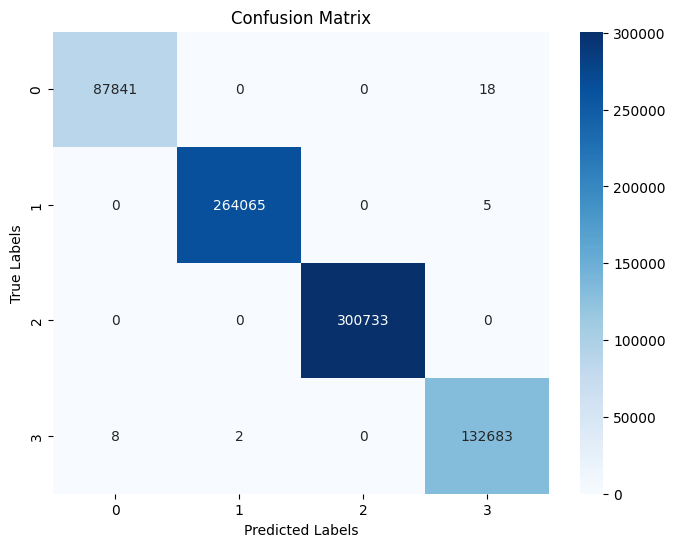

In [12]:

early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
cnn_gru_mdpi1 = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/updated_models/1st_round_CNN_GRU_MDPI_cate_model.h5')
cnn_gru_mdpi1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/category/client3_cnn_gru_mdpi_cate_1stFL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
cnn_gru_mdpi1.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = cnn_gru_mdpi1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [13]:
print(f"Accuracy for 4 class classification cnn_gru_mdpi_1stfl: {accuracy:.4f}")
print(f"Precision for 4 class classification cnn_gru_mdpi_1stfl fl: {precision:.4f}")
print(f"Recall for 4 class classification cnn_gru_mdpi_1stfl fl: {recall:.4f}")
print(f"F1 Score for 4 class classification cnn_gru_mdpi_1stfl fl: {f1:.4f}")
print(f"MCC for 4 class classification cnn_gru_mdpi_1stfl fl: {mcc:.4f}")

Accuracy for 4 class classification cnn_gru_mdpi_1stfl: 1.0000
Precision for 4 class classification cnn_gru_mdpi_1stfl fl: 0.9999
Recall for 4 class classification cnn_gru_mdpi_1stfl fl: 0.9999
F1 Score for 4 class classification cnn_gru_mdpi_1stfl fl: 0.9999
MCC for 4 class classification cnn_gru_mdpi_1stfl fl: 0.9999


2nd round

Epoch 1/5
45799/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9988 - loss: 0.0048
Epoch 1: val_loss improved from inf to 0.00090, saving model to D:/linthoi/FL_models/new/client3/category/client3_cnn_gru_mdpi_cate_2nd_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 150s 3ms/step - accuracy: 0.9988 - loss: 0.0048 - val_accuracy: 0.9999 - val_loss: 8.9610e-04
Epoch 2/5
45803/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9998 - loss: 0.0011
Epoch 2: val_loss did not improve from 0.00090
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 139s 3ms/step - accuracy: 0.9998 - loss: 0.0011 - val_accuracy: 0.9999 - val_loss: 0.0010
Epoch 3/5
45806/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9998 - loss: 8.6844e-04
Epoch 3: val_loss improved from 0.00090 to 0.00043, saving model to D:/linthoi/FL_models/new/client3/category/client3_cnn_gru_mdpi_cate_2nd_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 144s 3ms/step - accuracy: 0.9998 - loss: 8.6843e-04 - val_accuracy: 0.9999 - val_loss: 4.29

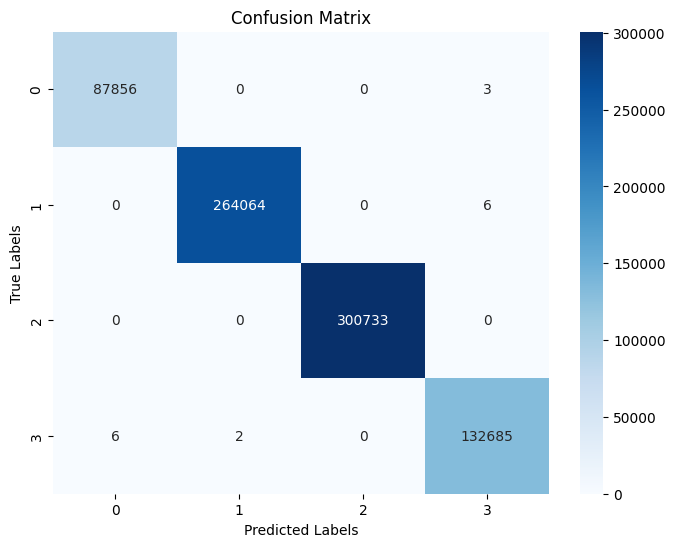

In [14]:


early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
cnn_gru_mdpi1 = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/updated_models/2nd_round_CNN_GRU_MDPI_cate_model.h5')
cnn_gru_mdpi1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/category/client3_cnn_gru_mdpi_cate_2nd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
cnn_gru_mdpi1.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = cnn_gru_mdpi1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [15]:
print(f"Accuracy for 4 class classification cnn_gru_mdpi_2ndfl: {accuracy:.4f}")
print(f"Precision for 4 class classification cnn_gru_mdpi_2ndfl fl: {precision:.4f}")
print(f"Recall for 4 class classification cnn_gru_mdpi_2ndfl fl: {recall:.4f}")
print(f"F1 Score for 4 class classification cnn_gru_mdpi_2ndfl fl: {f1:.4f}")
print(f"MCC for 4 class classification cnn_gru_mdpi_2ndfl fl: {mcc:.4f}")

Accuracy for 4 class classification cnn_gru_mdpi_2ndfl: 1.0000
Precision for 4 class classification cnn_gru_mdpi_2ndfl fl: 1.0000
Recall for 4 class classification cnn_gru_mdpi_2ndfl fl: 1.0000
F1 Score for 4 class classification cnn_gru_mdpi_2ndfl fl: 1.0000
MCC for 4 class classification cnn_gru_mdpi_2ndfl fl: 1.0000


pcc_cnn ieee binary before fl

Epoch 1/5
83022/83022 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9994 - loss: 0.0019
Epoch 1: val_loss improved from inf to 0.00000, saving model to D:/linthoi/FL_models/new/client3/binary/client3_pcc_cnn_ieee_binary_bfore_FL_weight_iid.keras
83022/83022 ━━━━━━━━━━━━━━━━━━━━ 580s 7ms/step - accuracy: 0.9994 - loss: 0.0019 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 2/5
83018/83022 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 8.9095e-13
Epoch 2: val_loss did not improve from 0.00000
83022/83022 ━━━━━━━━━━━━━━━━━━━━ 559s 7ms/step - accuracy: 1.0000 - loss: 8.9095e-13 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 3/5
83015/83022 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 1.0524e-10
Epoch 3: val_loss did not improve from 0.00000
83022/83022 ━━━━━━━━━━━━━━━━━━━━ 516s 6ms/step - accuracy: 1.0000 - loss: 1.0524e-10 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 4/5
83016/83022 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 1.0000 - loss: 2.

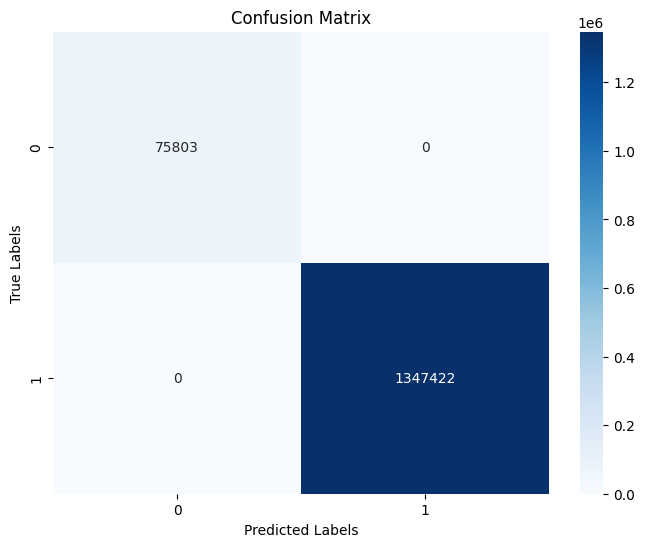

In [ ]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
pcc_cnn_ieee_binary = load_model(r'D:\linthoi\FL_models\new\glob_models\Binary_glob_model\firstinitialized\pcc_cnn_bin_glob_model.h5')
pcc_cnn_ieee_binary.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/binary/client3_pcc_cnn_ieee_binary_bfore_FL_weight_iid.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
pcc_cnn_ieee_binary.fit(X1_train, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = pcc_cnn_ieee_binary.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [19]:
print(f"Accuracy for 2 class classification pcc_cnn_bin_bforeFL: {accuracy:.4f}")
print(f"Precision for 2 class classification pcc_cnn_bin_bforeFL fl: {precision:.4f}")
print(f"Recall for 2 class classification pcc_cnn_bin_bforeFL fl: {recall:.4f}")
print(f"F1 Score for 2 class classification pcc_cnn_bin_bforeFL fl: {f1:.4f}")
print(f"MCC for 2 class classification pcc_cnn_bin_bforeFL fl: {mcc:.4f}")

Accuracy for 2 class classification pcc_cnn_bin_bforeFL: 1.0000
Precision for 2 class classification pcc_cnn_bin_bforeFL fl: 1.0000
Recall for 2 class classification pcc_cnn_bin_bforeFL fl: 1.0000
F1 Score for 2 class classification pcc_cnn_bin_bforeFL fl: 1.0000
MCC for 2 class classification pcc_cnn_bin_bforeFL fl: 1.0000


pcc cnn before fl 4 class classification (category)

Epoch 1/5
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9903 - loss: 0.0292
Epoch 1: val_loss improved from inf to 0.00081, saving model to D:/linthoi/FL_models/new/client3/category/client3_pcc_cnn_ieee_cate_bfore_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 291s 6ms/step - accuracy: 0.9903 - loss: 0.0292 - val_accuracy: 0.9998 - val_loss: 8.1148e-04
Epoch 2/5
45809/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9998 - loss: 7.5399e-04
Epoch 2: val_loss improved from 0.00081 to 0.00025, saving model to D:/linthoi/FL_models/new/client3/category/client3_pcc_cnn_ieee_cate_bfore_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 268s 6ms/step - accuracy: 0.9998 - loss: 7.5397e-04 - val_accuracy: 1.0000 - val_loss: 2.4780e-04
Epoch 3/5
45803/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9999 - loss: 6.4063e-04
Epoch 3: val_loss improved from 0.00025 to 0.00010, saving model to D:/linthoi/FL_models/new/client3/category/client3_pcc_cnn_ieee_cate_bfore_FL_weight.ker

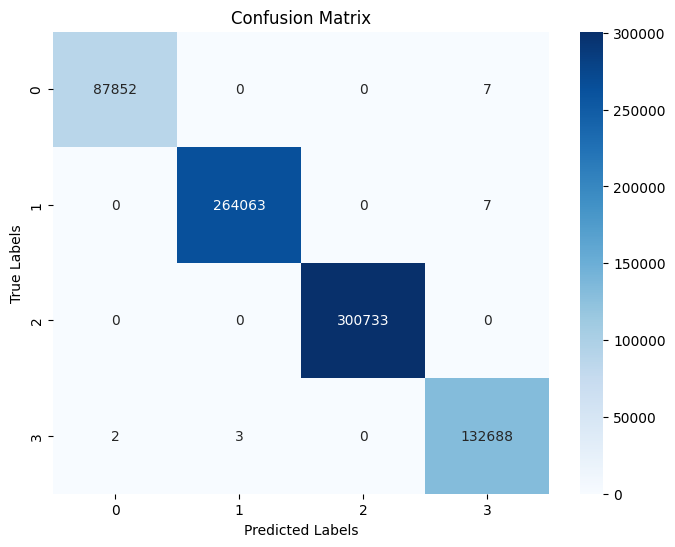

In [6]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
pcc_cnn = load_model(r'D:\linthoi\FL_models\new\glob_models\Category_glob_model\firstinitialized\pcc_cnn_cate_glob_model.h5')
pcc_cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/category/client3_pcc_cnn_ieee_cate_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
pcc_cnn.fit(X1_train, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = pcc_cnn.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [8]:
print(f"Accuracy for 4 class classification pcc_cnn_cate_bforeFL: {accuracy:.4f}")
print(f"Precision for 4 class classification pcc_cnn_cate_bforeFL fl: {precision:.4f}")
print(f"Recall for 4 class classification pcc_cnn_cate_bforeFL fl: {recall:.4f}")
print(f"F1 Score for 4 class classification pcc_cnn_cate_bforeFL fl: {f1:.4f}")
print(f"MCC for 4 class classification pcc_cnn_cate_bforeFL fl: {mcc:.4f}")

Accuracy for 4 class classification pcc_cnn_cate_bforeFL: 1.0000
Precision for 4 class classification pcc_cnn_cate_bforeFL fl: 1.0000
Recall for 4 class classification pcc_cnn_cate_bforeFL fl: 1.0000
F1 Score for 4 class classification pcc_cnn_cate_bforeFL fl: 1.0000
MCC for 4 class classification pcc_cnn_cate_bforeFL fl: 1.0000


1st FL round pcc_cnn cate model

Epoch 1/5
45810/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9992 - loss: 0.0024
Epoch 1: val_loss improved from inf to 0.00001, saving model to D:/linthoi/FL_models/new/client3/category/client3_pcc_cnn_ieee_cate_1st_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 200s 4ms/step - accuracy: 0.9992 - loss: 0.0024 - val_accuracy: 1.0000 - val_loss: 7.6830e-06
Epoch 2/5
45809/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9999 - loss: 3.0894e-04
Epoch 2: val_loss did not improve from 0.00001
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 204s 4ms/step - accuracy: 0.9999 - loss: 3.0894e-04 - val_accuracy: 1.0000 - val_loss: 2.0296e-05
Epoch 3/5
45804/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 1.9476e-04
Epoch 3: val_loss did not improve from 0.00001
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 214s 5ms/step - accuracy: 1.0000 - loss: 1.9478e-04 - val_accuracy: 1.0000 - val_loss: 3.3413e-05
Epoch 4/5
45805/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9999 - loss: 5.7359e-

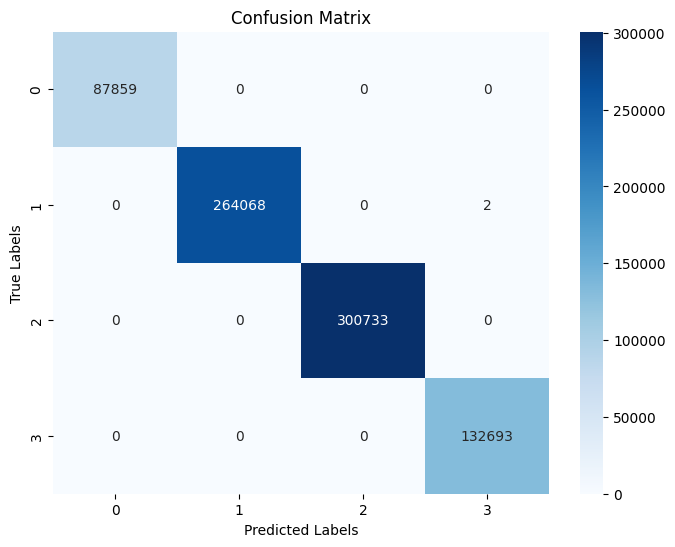

In [6]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
pcc_cnn = load_model("D:/linthoi/FL_models/new/glob_models/Category_glob_model/updated_models/1st_round_pcc_cnn_cate_glob_model.h5")
pcc_cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/category/client3_pcc_cnn_ieee_cate_1st_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
pcc_cnn.fit(X1_train, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = pcc_cnn.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [7]:
print(f"Accuracy for 4 class classification pcc_cnn_cate_1stFL: {accuracy:.4f}")
print(f"Precision for 4 class classification pcc_cnn_cate_1stFL fl: {precision:.4f}")
print(f"Recall for 4 class classification pcc_cnn_cate_1stFL fl: {recall:.4f}")
print(f"F1 Score for 4 class classification pcc_cnn_cate_1stFL fl: {f1:.4f}")
print(f"MCC for 4 class classification pcc_cnn_cate_1stFL fl: {mcc:.4f}")

Accuracy for 4 class classification pcc_cnn_cate_1stFL: 1.0000
Precision for 4 class classification pcc_cnn_cate_1stFL fl: 1.0000
Recall for 4 class classification pcc_cnn_cate_1stFL fl: 1.0000
F1 Score for 4 class classification pcc_cnn_cate_1stFL fl: 1.0000
MCC for 4 class classification pcc_cnn_cate_1stFL fl: 1.0000


PCC_CNN type classification before FL

Epoch 1/3
45810/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9883 - loss: 0.0397
Epoch 1: val_loss improved from inf to 0.00408, saving model to D:/linthoi/FL_models/new/client3/type/client3_pcc_cnn_ieee_type_bfore_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 304s 7ms/step - accuracy: 0.9883 - loss: 0.0397 - val_accuracy: 0.9986 - val_loss: 0.0041
Epoch 2/3
45804/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9986 - loss: 0.0050
Epoch 2: val_loss improved from 0.00408 to 0.00298, saving model to D:/linthoi/FL_models/new/client3/type/client3_pcc_cnn_ieee_type_bfore_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 242s 5ms/step - accuracy: 0.9986 - loss: 0.0050 - val_accuracy: 0.9991 - val_loss: 0.0030
Epoch 3/3
45808/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9989 - loss: 0.0037
Epoch 3: val_loss did not improve from 0.00298
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 230s 5ms/step - accuracy: 0.9989 - loss: 0.0037 - val_accuracy: 0.9992 - val_loss: 0.0031
Restoring mod

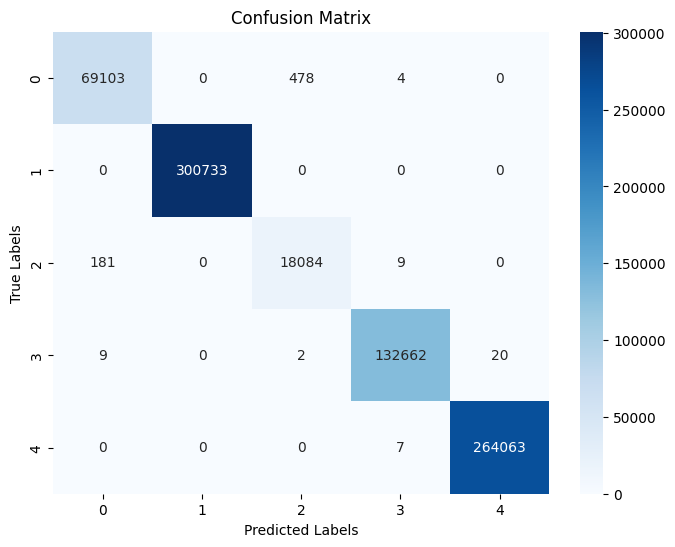

In [6]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
pcc_cnn_type = load_model(r'D:\linthoi\FL_models\new\glob_models\Type_glob_model\firstinitialized\pcc_cnn_type_glob_model.h5')
pcc_cnn_type.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/type/client3_pcc_cnn_ieee_type_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
pcc_cnn_type.fit(X1_train, y1_train, epochs=3, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = pcc_cnn_type.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [7]:
print(f"Accuracy for 4 class classification pcc_cnn_type_bforeFL: {accuracy:.4f}")
print(f"Precision for 4 class classification pcc_cnn_type_bforeFL fl: {precision:.4f}")
print(f"Recall for 4 class classification pcc_cnn_type_bforeFL fl: {recall:.4f}")
print(f"F1 Score for 4 class classification pcc_cnn_type_bforeFL fl: {f1:.4f}")
print(f"MCC for 4 class classification pcc_cnn_type_bforeFL fl: {mcc:.4f}")

Accuracy for 4 class classification pcc_cnn_type_bforeFL: 0.9991
Precision for 4 class classification pcc_cnn_type_bforeFL fl: 0.9942
Recall for 4 class classification pcc_cnn_type_bforeFL fl: 0.9965
F1 Score for 4 class classification pcc_cnn_type_bforeFL fl: 0.9953
MCC for 4 class classification pcc_cnn_type_bforeFL fl: 0.9987


1st fl round pcc_cnn type classification

Epoch 1/3
45806/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9921 - loss: 0.0360
Epoch 1: val_loss improved from inf to 0.00285, saving model to D:/linthoi/FL_models/new/client3/type/client3_pcc_cnn_ieee_type_1st_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 319s 7ms/step - accuracy: 0.9921 - loss: 0.0360 - val_accuracy: 0.9991 - val_loss: 0.0028
Epoch 2/3
45806/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9990 - loss: 0.0034
Epoch 2: val_loss improved from 0.00285 to 0.00241, saving model to D:/linthoi/FL_models/new/client3/type/client3_pcc_cnn_ieee_type_1st_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 299s 7ms/step - accuracy: 0.9990 - loss: 0.0034 - val_accuracy: 0.9992 - val_loss: 0.0024
Epoch 3/3
45805/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9990 - loss: 0.0032
Epoch 3: val_loss did not improve from 0.00241
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 251s 5ms/step - accuracy: 0.9990 - loss: 0.0032 - val_accuracy: 0.9992 - val_loss: 0.0028
Restoring model w

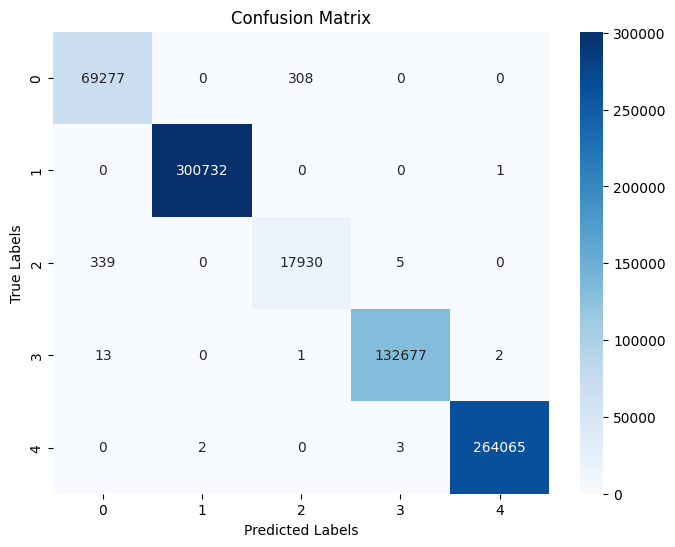

In [8]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
pcc_cnn_type = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/1st_round_pcc_cnn_type_glob_model.h5')
pcc_cnn_type.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/type/client3_pcc_cnn_ieee_type_1st_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
pcc_cnn_type.fit(X1_train, y1_train, epochs=3, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = pcc_cnn_type.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [9]:
print(f"Accuracy for 5 class classification pcc_cnn_type_bforeFL: {accuracy:.4f}")
print(f"Precision for 5 class classification pcc_cnn_type_bforeFL fl: {precision:.4f}")
print(f"Recall for 5 class classification pcc_cnn_type_bforeFL fl: {recall:.4f}")
print(f"F1 Score for 5 class classification pcc_cnn_type_bforeFL fl: {f1:.4f}")
print(f"MCC for 5 class classification pcc_cnn_type_bforeFL fl: {mcc:.4f}")

Accuracy for 5 class classification pcc_cnn_type_bforeFL: 0.9991
Precision for 5 class classification pcc_cnn_type_bforeFL fl: 0.9956
Recall for 5 class classification pcc_cnn_type_bforeFL fl: 0.9953
F1 Score for 5 class classification pcc_cnn_type_bforeFL fl: 0.9955
MCC for 5 class classification pcc_cnn_type_bforeFL fl: 0.9988


2nd fl round pcc_cnn type classification

Epoch 1/3
45812/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9931 - loss: 0.0370
Epoch 1: val_loss improved from inf to 0.00486, saving model to D:/linthoi/FL_models/new/client3/type/client3_pcc_cnn_ieee_type_2nd_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 313s 7ms/step - accuracy: 0.9931 - loss: 0.0370 - val_accuracy: 0.9989 - val_loss: 0.0049
Epoch 2/3
45812/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9990 - loss: 0.0034
Epoch 2: val_loss improved from 0.00486 to 0.00243, saving model to D:/linthoi/FL_models/new/client3/type/client3_pcc_cnn_ieee_type_2nd_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 367s 8ms/step - accuracy: 0.9990 - loss: 0.0034 - val_accuracy: 0.9992 - val_loss: 0.0024
Epoch 3/3
45811/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9991 - loss: 0.0032
Epoch 3: val_loss improved from 0.00243 to 0.00233, saving model to D:/linthoi/FL_models/new/client3/type/client3_pcc_cnn_ieee_type_2nd_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 35

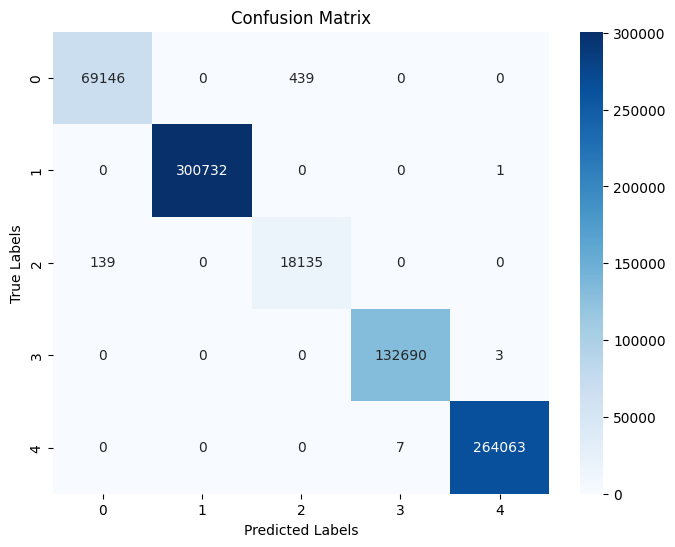

In [7]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
pcc_cnn_type = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/2nd_round_pcc_cnn_type_glob_model.h5')
pcc_cnn_type.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/type/client3_pcc_cnn_ieee_type_2nd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
pcc_cnn_type.fit(X1_train, y1_train, epochs=3, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = pcc_cnn_type.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [8]:
print(f"Accuracy for 5 class classification pcc_cnn_type_2nd FL: {accuracy:.4f}")
print(f"Precision for 5 class classification pcc_cnn_type_2nd fl: {precision:.4f}")
print(f"Recall for 5 class classification pcc_cnn_type_2nd fl: {recall:.4f}")
print(f"F1 Score for 5 class classification pcc_cnn_type_2nd fl: {f1:.4f}")
print(f"MCC for 5 class classification pcc_cnn_type_2nd fl: {mcc:.4f}")

Accuracy for 5 class classification pcc_cnn_type_2nd FL: 0.9993
Precision for 5 class classification pcc_cnn_type_2nd fl: 0.9949
Recall for 5 class classification pcc_cnn_type_2nd fl: 0.9972
F1 Score for 5 class classification pcc_cnn_type_2nd fl: 0.9960
MCC for 5 class classification pcc_cnn_type_2nd fl: 0.9989


3rd fl round pcc_cnn type classification


Epoch 1/3
45808/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9951 - loss: 0.0214
Epoch 1: val_loss improved from inf to 0.00265, saving model to D:/linthoi/FL_models/new/client3/type/client3_pcc_cnn_ieee_type_3rd_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 346s 7ms/step - accuracy: 0.9951 - loss: 0.0214 - val_accuracy: 0.9991 - val_loss: 0.0026
Epoch 2/3
45808/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9990 - loss: 0.0032
Epoch 2: val_loss improved from 0.00265 to 0.00221, saving model to D:/linthoi/FL_models/new/client3/type/client3_pcc_cnn_ieee_type_3rd_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 315s 7ms/step - accuracy: 0.9990 - loss: 0.0032 - val_accuracy: 0.9994 - val_loss: 0.0022
Epoch 3/3
45807/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9991 - loss: 0.0031
Epoch 3: val_loss did not improve from 0.00221
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 270s 6ms/step - accuracy: 0.9991 - loss: 0.0031 - val_accuracy: 0.9992 - val_loss: 0.0025
Restoring model w

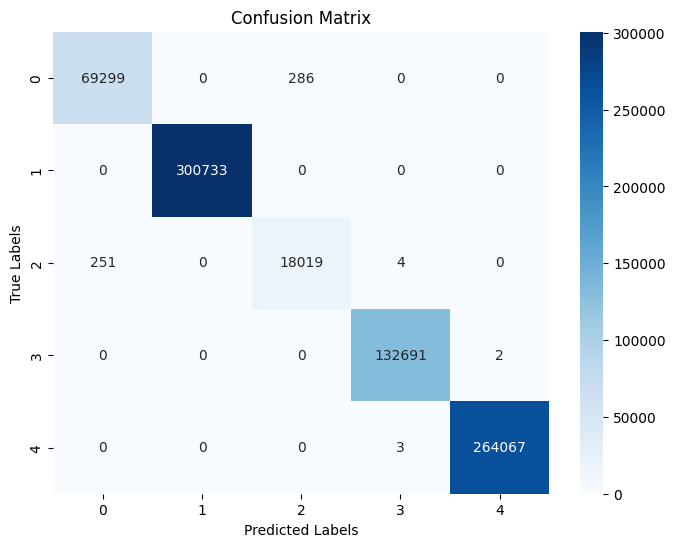

In [9]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
pcc_cnn_type = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/3rd_round_pcc_cnn_type_glob_model.h5')
pcc_cnn_type.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/type/client3_pcc_cnn_ieee_type_3rd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
pcc_cnn_type.fit(X1_train, y1_train, epochs=3, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = pcc_cnn_type.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [10]:
print(f"Accuracy for 5 class classification pcc_cnn_type_3rd FL: {accuracy:.4f}")
print(f"Precision for 5 class classification pcc_cnn_type_3rd fl: {precision:.4f}")
print(f"Recall for 5 class classification pcc_cnn_type_3rd fl: {recall:.4f}")
print(f"F1 Score for 5 class classification pcc_cnn_type_3rd fl: {f1:.4f}")
print(f"MCC for 5 class classification pcc_cnn_type_3rd fl: {mcc:.4f}")

Accuracy for 5 class classification pcc_cnn_type_3rd FL: 0.9993
Precision for 5 class classification pcc_cnn_type_3rd fl: 0.9961
Recall for 5 class classification pcc_cnn_type_3rd fl: 0.9964
F1 Score for 5 class classification pcc_cnn_type_3rd fl: 0.9963
MCC for 5 class classification pcc_cnn_type_3rd fl: 0.9990


FELIDS dnn 4 class classification before fl (category)

45813/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9814 - loss: 0.0535
Epoch 1: val_loss improved from inf to 0.00029, saving model to D:/linthoi/FL_models/new/client3/category/client3_FELIDS_dnn_bfore_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 343s 7ms/step - accuracy: 0.9814 - loss: 0.0535 - val_accuracy: 0.9999 - val_loss: 2.9186e-04
Restoring model weights from the end of the best epoch: 1.
24543/24543 ━━━━━━━━━━━━━━━━━━━━ 55s 2ms/step
Accuracy Score: 0.9999452476905348


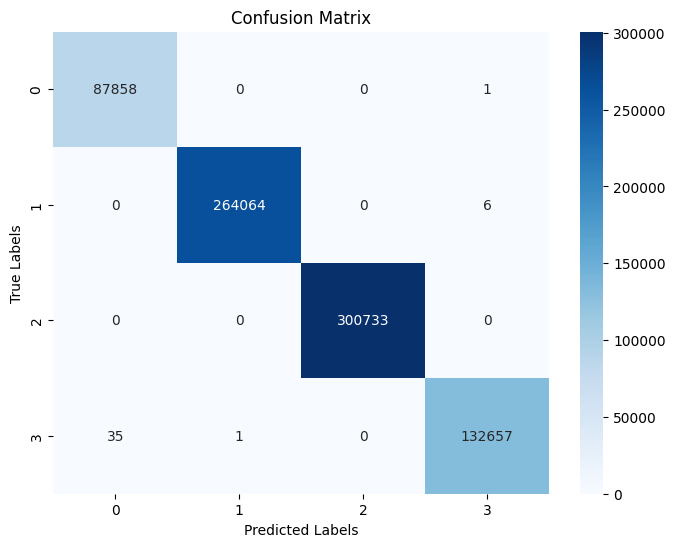

In [8]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_dnn_cate = load_model(r'D:\linthoi\FL_models\new\glob_models\Category_glob_model\firstinitialized\felids_dnn_cate.h5')
felids_dnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/category/client3_FELIDS_dnn_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_dnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_dnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [9]:
print(f"Accuracy for 4 class classification felids_dnn_cate before fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_dnn_cate before fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_dnn_cate before fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_dnn_cate before fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_dnn_cate before fl: {mcc:.4f}")

Accuracy for 4 class classification felids_dnn_cate before fl: 0.9999
Precision for 4 class classification felids_dnn_cate before fl: 0.9999
Recall for 4 class classification felids_dnn_cate before fl: 0.9999
F1 Score for 4 class classification felids_dnn_cate before fl: 0.9999
MCC for 4 class classification felids_dnn_cate before fl: 0.9999


1st fl round

45805/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9967 - loss: 0.0103
Epoch 1: val_loss improved from inf to 0.00007, saving model to D:/linthoi/FL_models/new/client3/category/client3_FELIDS_dnn_1st_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 238s 5ms/step - accuracy: 0.9967 - loss: 0.0103 - val_accuracy: 1.0000 - val_loss: 7.0726e-05
Restoring model weights from the end of the best epoch: 1.
24543/24543 ━━━━━━━━━━━━━━━━━━━━ 40s 2ms/step
Accuracy Score: 0.9999936334523878


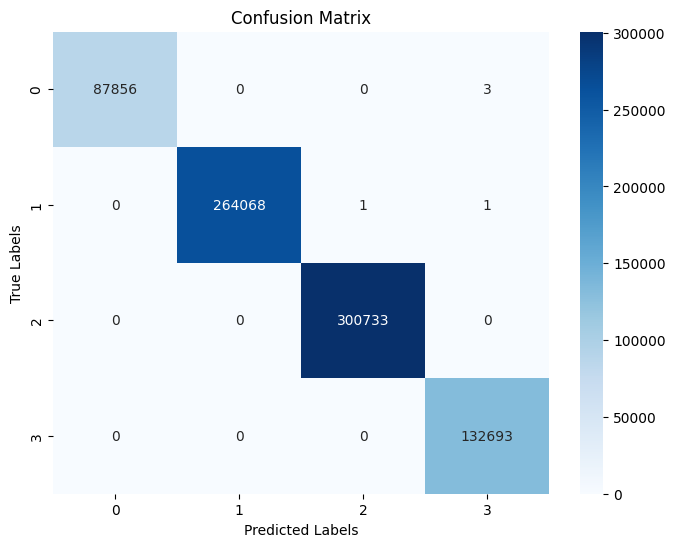

In [10]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_dnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/updated_models/1st_round_felids_dnn_cate_glob_model.h5')
felids_dnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/category/client3_FELIDS_dnn_1st_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_dnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_dnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [11]:
print(f"Accuracy for 4 class classification felids_dnn_cate 1st fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_dnn_cate 1st fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_dnn_cate 1st fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_dnn_cate 1st fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_dnn_cate 1st fl: {mcc:.4f}")

Accuracy for 4 class classification felids_dnn_cate 1st fl: 1.0000
Precision for 4 class classification felids_dnn_cate 1st fl: 1.0000
Recall for 4 class classification felids_dnn_cate 1st fl: 1.0000
F1 Score for 4 class classification felids_dnn_cate 1st fl: 1.0000
MCC for 4 class classification felids_dnn_cate 1st fl: 1.0000


Felids DNN Type classification before FL

45791/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9670 - loss: 0.1041
Epoch 1: val_loss improved from inf to 0.02124, saving model to D:/linthoi/FL_models/new/client3/type/client3_felids_dnn_type_bfore_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 111s 2ms/step - accuracy: 0.9670 - loss: 0.1040 - val_accuracy: 0.9955 - val_loss: 0.0212
Restoring model weights from the end of the best epoch: 1.
24543/24543 ━━━━━━━━━━━━━━━━━━━━ 31s 1ms/step
Accuracy Score: 0.9954950309095887


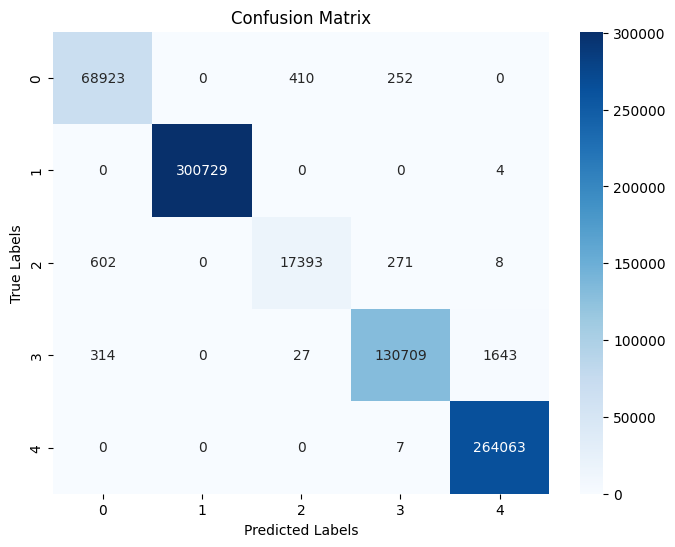

In [6]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_dnn_type = load_model(r'D:\linthoi\FL_models\new\glob_models\Type_glob_model\firstinitialized\felids_dnn_type.h5')
felids_dnn_type.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/type/client3_felids_dnn_type_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_dnn_type.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_dnn_type.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

In [7]:
print(f"Accuracy for 5 class classification felids_dnn_type before fl: {accuracy:.4f}")
print(f"Precision for 5 class classification felids_dnn_type before fl: {precision:.4f}")
print(f"Recall for 5 class classification felids_dnn_type before fl: {recall:.4f}")
print(f"F1 Score for 5 class classification felids_dnn_type before fl: {f1:.4f}")
print(f"MCC for 5 class classification felids_dnn_type before fl: {mcc:.4f}")

Accuracy for 5 class classification felids_dnn_type before fl: 0.9955
Precision for 5 class classification felids_dnn_type before fl: 0.9904
Recall for 5 class classification felids_dnn_type before fl: 0.9855
F1 Score for 5 class classification felids_dnn_type before fl: 0.9879
MCC for 5 class classification felids_dnn_type before fl: 0.9936


felids dnn type 1st fl round

45800/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9433 - loss: 0.4486
Epoch 1: val_loss improved from inf to 0.00722, saving model to D:/linthoi/FL_models/new/client3/type/client3_felids_dnn_type_1st_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 176s 4ms/step - accuracy: 0.9433 - loss: 0.4485 - val_accuracy: 0.9983 - val_loss: 0.0072
Restoring model weights from the end of the best epoch: 1.
24543/24543 ━━━━━━━━━━━━━━━━━━━━ 33s 1ms/step
Accuracy Score: 0.998244106168548


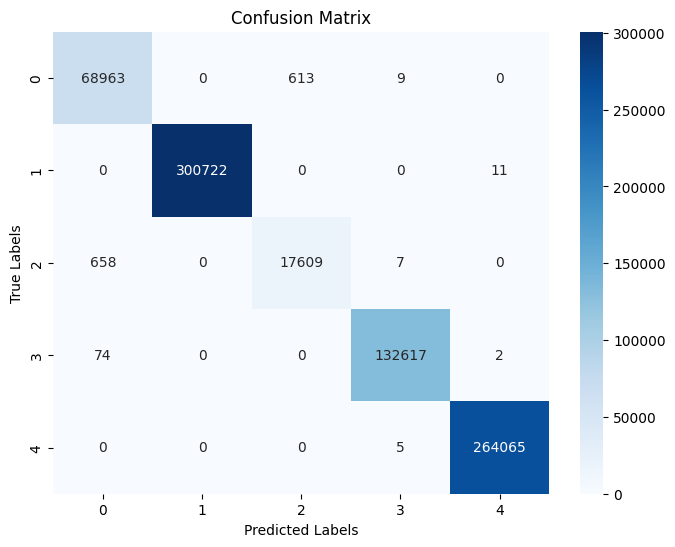

In [8]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_dnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/1st_round_felids_dnn_type_glob_model.h5')
felids_dnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/type/client3_felids_dnn_type_1st_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_dnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_dnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [9]:
print(f"Accuracy for 4 class classification felids_dnn_type 1st fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_dnn_type 1st fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_dnn_type 1st fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_dnn_type 1st fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_dnn_type 1st fl: {mcc:.4f}")

Accuracy for 4 class classification felids_dnn_type 1st fl: 0.9982
Precision for 4 class classification felids_dnn_type 1st fl: 0.9911
Recall for 4 class classification felids_dnn_type 1st fl: 0.9908
F1 Score for 4 class classification felids_dnn_type 1st fl: 0.9910
MCC for 4 class classification felids_dnn_type 1st fl: 0.9975


2nd felids round for type classification

45813/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9638 - loss: 0.1887
Epoch 1: val_loss improved from inf to 0.00605, saving model to D:/linthoi/FL_models/new/client3/type/client3_felids_dnn_type_2nd_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 191s 4ms/step - accuracy: 0.9638 - loss: 0.1887 - val_accuracy: 0.9984 - val_loss: 0.0060
Restoring model weights from the end of the best epoch: 1.
24543/24543 ━━━━━━━━━━━━━━━━━━━━ 36s 1ms/step
Accuracy Score: 0.9983663438827027


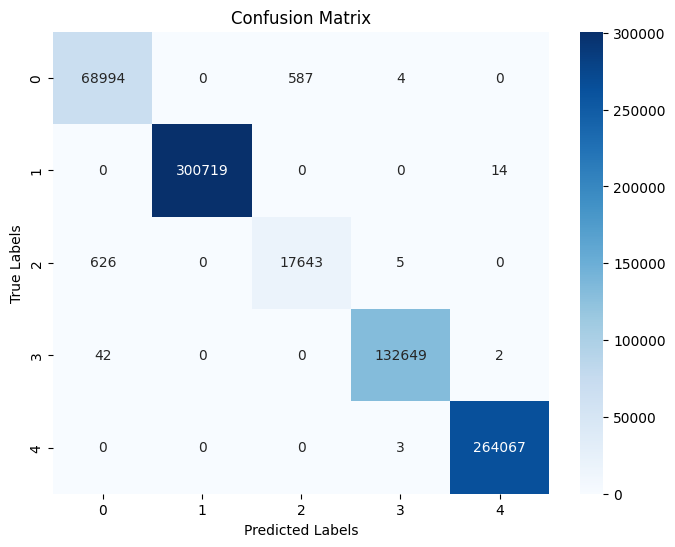

In [10]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_dnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/2nd_round_felids_dnn_type_glob_model.h5')
felids_dnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/type/client3_felids_dnn_type_2nd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_dnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_dnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [11]:
print(f"Accuracy for 4 class classification felids_dnn_type 2nd fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_dnn_type 2nd fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_dnn_type 2nd fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_dnn_type 2nd fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_dnn_type 2nd fl: {mcc:.4f}")

Accuracy for 4 class classification felids_dnn_type 2nd fl: 0.9984
Precision for 4 class classification felids_dnn_type 2nd fl: 0.9916
Recall for 4 class classification felids_dnn_type 2nd fl: 0.9913
F1 Score for 4 class classification felids_dnn_type 2nd fl: 0.9915
MCC for 4 class classification felids_dnn_type 2nd fl: 0.9977


3rd felids dnn type classification round

45806/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9720 - loss: 0.1560
Epoch 1: val_loss improved from inf to 0.00635, saving model to D:/linthoi/FL_models/new/client3/type/client3_felids_dnn_type_3rd_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 193s 4ms/step - accuracy: 0.9720 - loss: 0.1559 - val_accuracy: 0.9985 - val_loss: 0.0064
Restoring model weights from the end of the best epoch: 1.
24543/24543 ━━━━━━━━━━━━━━━━━━━━ 32s 1ms/step
Accuracy Score: 0.9983612506446129


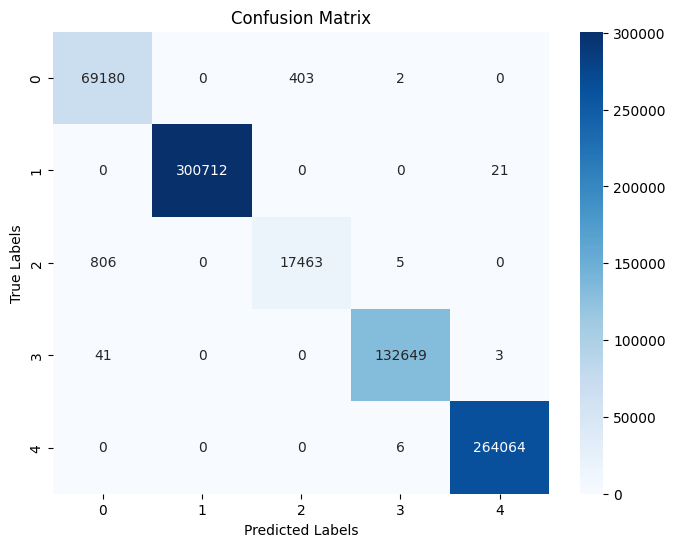

In [12]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_dnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/3rd_round_felids_dnn_type_glob_model.h5')
felids_dnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/type/client3_felids_dnn_type_3rd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_dnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_dnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [13]:
print(f"Accuracy for 4 class classification felids_dnn_type 3rd fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_dnn_type 3rd fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_dnn_type 3rd fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_dnn_type 3rd fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_dnn_type 3rd fl: {mcc:.4f}")

Accuracy for 4 class classification felids_dnn_type 3rd fl: 0.9984
Precision for 4 class classification felids_dnn_type 3rd fl: 0.9930
Recall for 4 class classification felids_dnn_type 3rd fl: 0.9899
F1 Score for 4 class classification felids_dnn_type 3rd fl: 0.9914
MCC for 4 class classification felids_dnn_type 3rd fl: 0.9977


FELIDS CNN 4 class classification (category) before fl

45811/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9541 - loss: 0.1100
Epoch 1: val_loss improved from inf to 0.00275, saving model to D:/linthoi/FL_models/new/client3/category/client3_FELIDS_cnn_CATE_bfore_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 265s 6ms/step - accuracy: 0.9541 - loss: 0.1100 - val_accuracy: 0.9991 - val_loss: 0.0027
Restoring model weights from the end of the best epoch: 1.
24543/24543 ━━━━━━━━━━━━━━━━━━━━ 65s 3ms/step
Accuracy Score: 0.9990322847629416


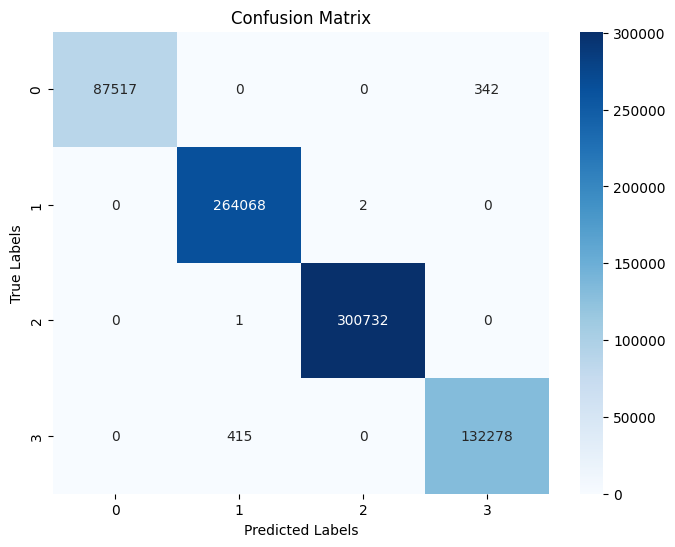

In [6]:

early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_dnn_cate = load_model(r'D:\linthoi\FL_models\new\glob_models\Category_glob_model\firstinitialized\felids_cnn_cate_glob_model.h5')
felids_dnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/category/client3_FELIDS_cnn_CATE_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_dnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_dnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [7]:
print(f"Accuracy for 4 class classification felids_cnn_cate before fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_cnn_cate before fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_cnn_cate before fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_cnn_cate before fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_cnn_cate before fl: {mcc:.4f}")

Accuracy for 4 class classification felids_cnn_cate before fl: 0.9990
Precision for 4 class classification felids_cnn_cate before fl: 0.9990
Recall for 4 class classification felids_cnn_cate before fl: 0.9982
F1 Score for 4 class classification felids_cnn_cate before fl: 0.9986
MCC for 4 class classification felids_cnn_cate before fl: 0.9986


In [8]:
felids_dnn_cate.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_4 (Conv1D)               │ (None, 70, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 68, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_6 (Conv1D)               │ (None, 66, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 120)            │        15,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 120)            │        14,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 4)              │           484 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 234,110 (914.50 KB)

 Trainable params: 78,036 (304.83 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 156,074 (609.67 KB)

1st fl cate cnn felids round

45809/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9912 - loss: 0.0251
Epoch 1: val_loss improved from inf to 0.00031, saving model to D:/linthoi/FL_models/new/client3/category/client3_FELIDS_cnn_CATE_1st_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 300s 7ms/step - accuracy: 0.9912 - loss: 0.0251 - val_accuracy: 0.9999 - val_loss: 3.1179e-04
Restoring model weights from the end of the best epoch: 1.
24543/24543 ━━━━━━━━━━━━━━━━━━━━ 78s 3ms/step
Accuracy Score: 0.9999121416429513


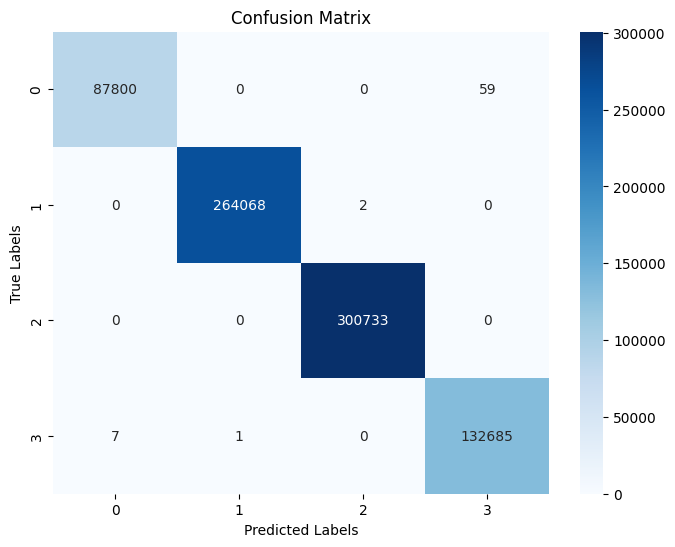

In [9]:


early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/updated_models/1st_round_felids_cnn_cate_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/category/client3_FELIDS_cnn_CATE_1st_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [10]:
print(f"Accuracy for 4 class classification felids_cnn_cate 1st fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_cnn_cate 1st fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_cnn_cate 1st fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_cnn_cate 1st fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_cnn_cate 1st fl: {mcc:.4f}")

Accuracy for 4 class classification felids_cnn_cate 1st fl: 0.9999
Precision for 4 class classification felids_cnn_cate 1st fl: 0.9999
Recall for 4 class classification felids_cnn_cate 1st fl: 0.9998
F1 Score for 4 class classification felids_cnn_cate 1st fl: 0.9998
MCC for 4 class classification felids_cnn_cate 1st fl: 0.9999


2nd fl round felids cnn category

45806/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9981 - loss: 0.0062
Epoch 1: val_loss improved from inf to 0.00030, saving model to D:/linthoi/FL_models/new/client3/category/client3_FELIDS_cnn_CATE_2nd_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 325s 7ms/step - accuracy: 0.9981 - loss: 0.0062 - val_accuracy: 0.9999 - val_loss: 3.0415e-04
Restoring model weights from the end of the best epoch: 1.
24543/24543 ━━━━━━━━━━━━━━━━━━━━ 72s 3ms/step
Accuracy Score: 0.9999248747381757


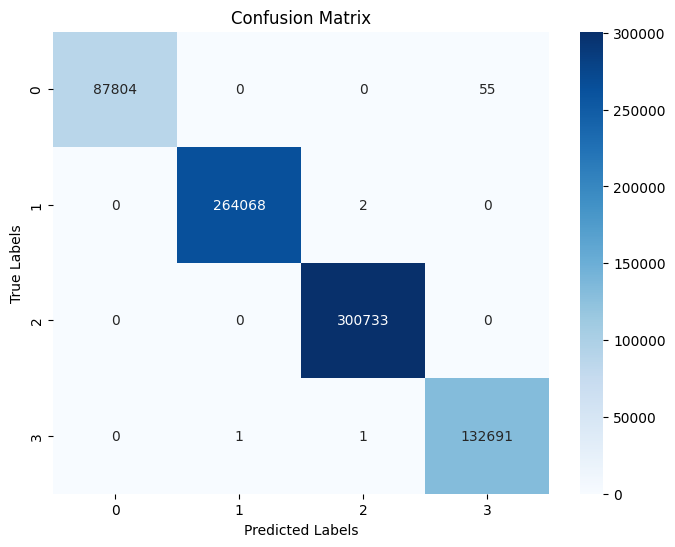

In [11]:


early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/updated_models/2nd_round_felids_cnn_cate_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/category/client3_FELIDS_cnn_CATE_2nd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [12]:
print(f"Accuracy for 4 class classification felids_cnn_cate 2nd fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_cnn_cate 2nd fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_cnn_cate 2nd fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_cnn_cate 2nd fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_cnn_cate 2nd fl: {mcc:.4f}")

Accuracy for 4 class classification felids_cnn_cate 2nd fl: 0.9999
Precision for 4 class classification felids_cnn_cate 2nd fl: 0.9999
Recall for 4 class classification felids_cnn_cate 2nd fl: 0.9998
F1 Score for 4 class classification felids_cnn_cate 2nd fl: 0.9999
MCC for 4 class classification felids_cnn_cate 2nd fl: 0.9999


3rd fl round felids cnn category

45810/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9994 - loss: 0.0034
Epoch 1: val_loss improved from inf to 0.00006, saving model to D:/linthoi/FL_models/new/client3/category/client3_FELIDS_cnn_CATE_3rd_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 254s 5ms/step - accuracy: 0.9994 - loss: 0.0034 - val_accuracy: 1.0000 - val_loss: 6.0456e-05
Restoring model weights from the end of the best epoch: 1.
24543/24543 ━━━━━━━━━━━━━━━━━━━━ 66s 3ms/step
Accuracy Score: 0.9999859935952531


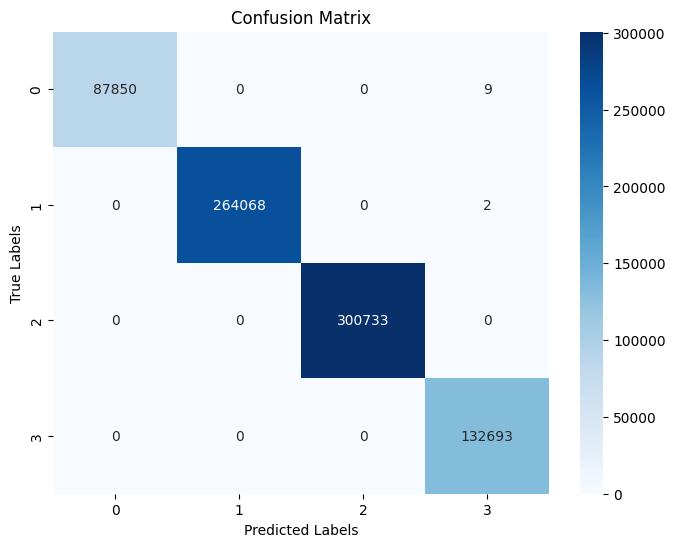

In [6]:


early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/updated_models/3rd_round_felids_cnn_cate_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/category/client3_FELIDS_cnn_CATE_3rd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [7]:
print(f"Accuracy for 4 class classification felids_cnn_cate 3rd fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_cnn_cate 3rd fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_cnn_cate 3rd fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_cnn_cate 3rd fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_cnn_cate 3rd fl: {mcc:.4f}")

Accuracy for 4 class classification felids_cnn_cate 3rd fl: 1.0000
Precision for 4 class classification felids_cnn_cate 3rd fl: 1.0000
Recall for 4 class classification felids_cnn_cate 3rd fl: 1.0000
F1 Score for 4 class classification felids_cnn_cate 3rd fl: 1.0000
MCC for 4 class classification felids_cnn_cate 3rd fl: 1.0000


felids cnn type before fl

45809/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9356 - loss: 0.1597
Epoch 1: val_loss improved from inf to 0.00515, saving model to D:/linthoi/FL_models/new/client3/type/client3_FELIDS_cnn_type_bfore_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 271s 6ms/step - accuracy: 0.9356 - loss: 0.1597 - val_accuracy: 0.9986 - val_loss: 0.0052
Restoring model weights from the end of the best epoch: 1.
24543/24543 ━━━━━━━━━━━━━━━━━━━━ 64s 3ms/step
Accuracy Score: 0.9983663438827027


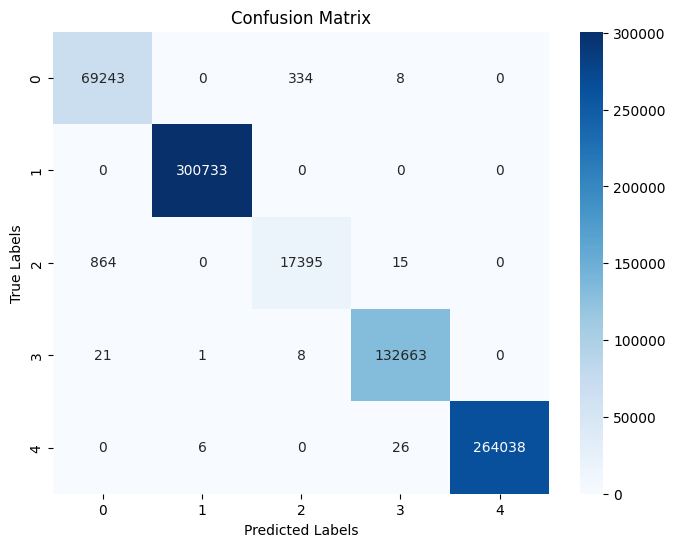

In [14]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model(r'D:\linthoi\FL_models\new\glob_models\Type_glob_model\firstinitialized\felids_cnn_type_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/type/client3_FELIDS_cnn_type_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [15]:
print(f"Accuracy for 5 class classification felids_cnn_type before fl: {accuracy:.4f}")
print(f"Precision for 5 class classification felids_cnn_type before fl: {precision:.4f}")
print(f"Recall for 5 class classification felids_cnn_type before fl: {recall:.4f}")
print(f"F1 Score for 5 class classification felids_cnn_type before fl: {f1:.4f}")
print(f"MCC for 5 class classification felids_cnn_type before fl: {mcc:.4f}")

Accuracy for 5 class classification felids_cnn_type before fl: 0.9984
Precision for 5 class classification felids_cnn_type before fl: 0.9935
Recall for 5 class classification felids_cnn_type before fl: 0.9893
F1 Score for 5 class classification felids_cnn_type before fl: 0.9914
MCC for 5 class classification felids_cnn_type before fl: 0.9977


1st fl round for felids cnn type 

45802/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9866 - loss: 0.0413
Epoch 1: val_loss improved from inf to 0.00558, saving model to D:/linthoi/FL_models/new/client3/type/client3_FELIDS_cnn_type_1st_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 245s 5ms/step - accuracy: 0.9866 - loss: 0.0413 - val_accuracy: 0.9988 - val_loss: 0.0056
Restoring model weights from the end of the best epoch: 1.
24543/24543 ━━━━━━━━━━━━━━━━━━━━ 55s 2ms/step
Accuracy Score: 0.9986923111204488


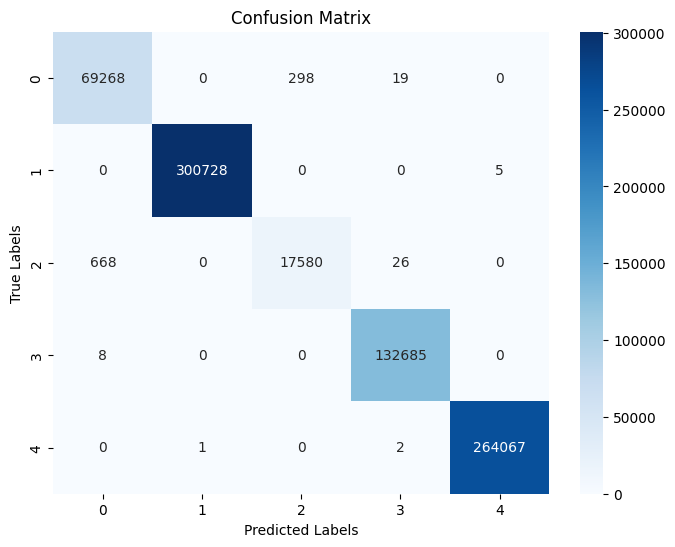

In [16]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/1st_round_felids_cnn_type_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/type/client3_FELIDS_cnn_type_1st_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [17]:
print(f"Accuracy for 5 class classification felids_cnn_type 1st fl: {accuracy:.4f}")
print(f"Precision for 5 class classification felids_cnn_type 1st fl: {precision:.4f}")
print(f"Recall for 5 class classification felids_cnn_type 1st fl: {recall:.4f}")
print(f"F1 Score for 5 class classification felids_cnn_type 1st fl: {f1:.4f}")
print(f"MCC for 5 class classification felids_cnn_type 1st fl: {mcc:.4f}")

Accuracy for 5 class classification felids_cnn_type 1st fl: 0.9987
Precision for 5 class classification felids_cnn_type 1st fl: 0.9947
Recall for 5 class classification felids_cnn_type 1st fl: 0.9915
F1 Score for 5 class classification felids_cnn_type 1st fl: 0.9930
MCC for 5 class classification felids_cnn_type 1st fl: 0.9981


2nd fl round felids cnn type 

45813/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9909 - loss: 0.0296
Epoch 1: val_loss improved from inf to 0.00678, saving model to D:/linthoi/FL_models/new/client3/type/client3_FELIDS_cnn_type_2nd_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 284s 6ms/step - accuracy: 0.9909 - loss: 0.0296 - val_accuracy: 0.9980 - val_loss: 0.0068
Restoring model weights from the end of the best epoch: 1.
24543/24543 ━━━━━━━━━━━━━━━━━━━━ 70s 3ms/step
Accuracy Score: 0.997883759573696


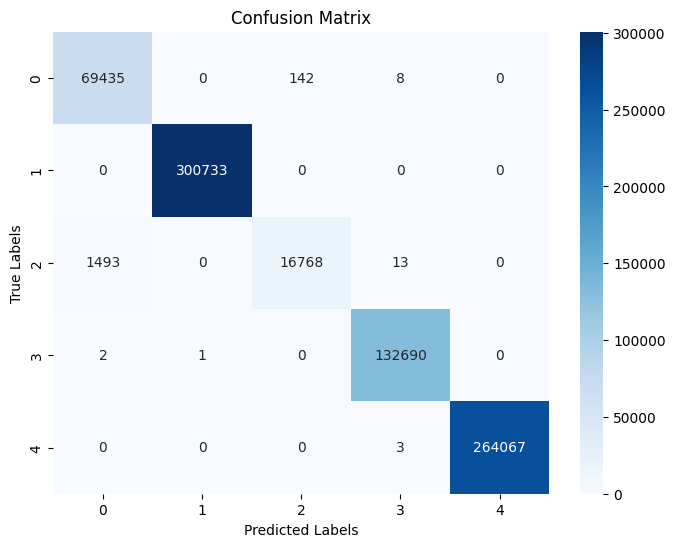

In [7]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/2nd_round_felids_cnn_type_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/type/client3_FELIDS_cnn_type_2nd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [8]:
print(f"Accuracy for 5 class classification felids_cnn_type 2nd fl: {accuracy:.4f}")
print(f"Precision for 5 class classification felids_cnn_type 2nd fl: {precision:.4f}")
print(f"Recall for 5 class classification felids_cnn_type 2nd fl: {recall:.4f}")
print(f"F1 Score for 5 class classification felids_cnn_type 2nd fl: {f1:.4f}")
print(f"MCC for 5 class classification felids_cnn_type 2nd fl: {mcc:.4f}")

Accuracy for 5 class classification felids_cnn_type 2nd fl: 0.9979
Precision for 5 class classification felids_cnn_type 2nd fl: 0.9941
Recall for 5 class classification felids_cnn_type 2nd fl: 0.9831
F1 Score for 5 class classification felids_cnn_type 2nd fl: 0.9883
MCC for 5 class classification felids_cnn_type 2nd fl: 0.9970


3rd fl felids cnn type classification round

45809/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9921 - loss: 0.0273
Epoch 1: val_loss improved from inf to 0.00448, saving model to D:/linthoi/FL_models/new/client3/type/client3_FELIDS_cnn_type_3rd_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 293s 6ms/step - accuracy: 0.9921 - loss: 0.0273 - val_accuracy: 0.9989 - val_loss: 0.0045
Restoring model weights from the end of the best epoch: 1.
24543/24543 ━━━━━━━━━━━━━━━━━━━━ 68s 3ms/step
Accuracy Score: 0.9987597965251384


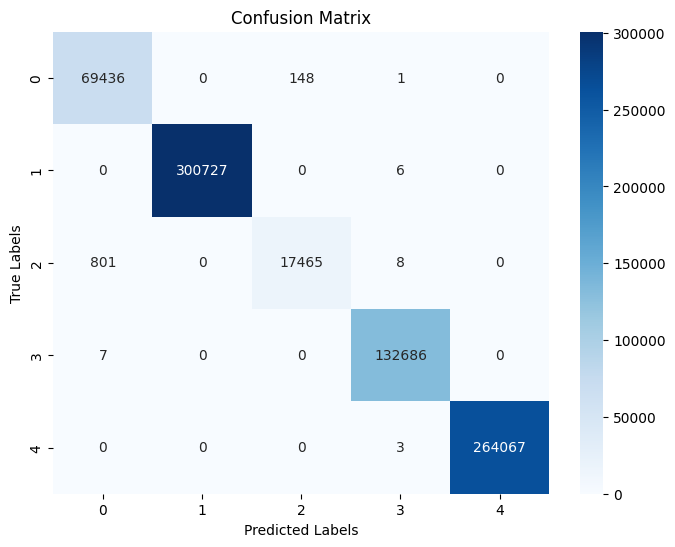

In [10]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/3rd_round_felids_cnn_type_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/type/client3_FELIDS_cnn_type_3rd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [11]:
print(f"Accuracy for 5 class classification felids_cnn_type 3rd fl: {accuracy:.4f}")
print(f"Precision for 5 class classification felids_cnn_type 3rd fl: {precision:.4f}")
print(f"Recall for 5 class classification felids_cnn_type 3rd fl: {recall:.4f}")
print(f"F1 Score for 5 class classification felids_cnn_type 3rd fl: {f1:.4f}")
print(f"MCC for 5 class classification felids_cnn_type 3rd fl: {mcc:.4f}")

Accuracy for 5 class classification felids_cnn_type 3rd fl: 0.9988
Precision for 5 class classification felids_cnn_type 3rd fl: 0.9960
Recall for 5 class classification felids_cnn_type 3rd fl: 0.9907
F1 Score for 5 class classification felids_cnn_type 3rd fl: 0.9933
MCC for 5 class classification felids_cnn_type 3rd fl: 0.9982


felids RNN category classification before FL

45812/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.9340 - loss: 0.1685
Epoch 1: val_loss improved from inf to 0.00019, saving model to D:/linthoi/FL_models/new/client3/category/client3_FELIDS_rnn_cate_bfore_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 3467s 76ms/step - accuracy: 0.9340 - loss: 0.1685 - val_accuracy: 1.0000 - val_loss: 1.9353e-04
Restoring model weights from the end of the best epoch: 1.
24543/24543 ━━━━━━━━━━━━━━━━━━━━ 477s 19ms/step
Accuracy Score: 0.999965620642894


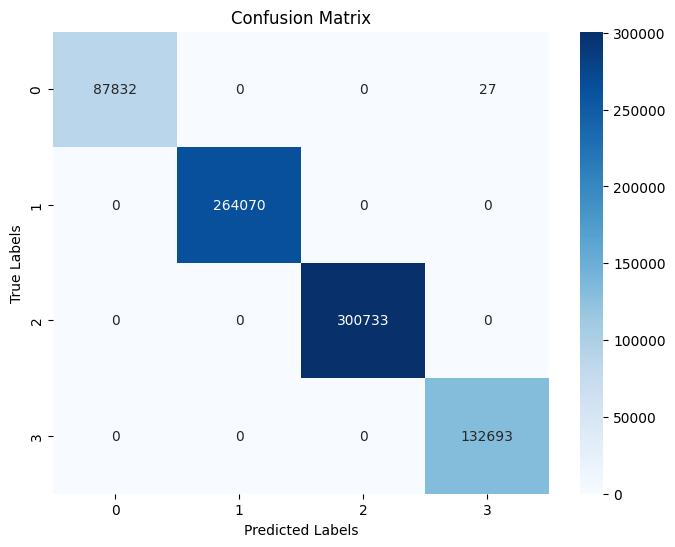

In [14]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/firstinitialized/felids_RNN_cate.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/category/client3_FELIDS_rnn_cate_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [15]:
print(f"Accuracy for 4 class classification felids_rnn_cate_bfore fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_rnn_cate_bfore  fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_rnn_cate_bfore  fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_rnn_cate_bfore  fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_rnn_cate_bfore  fl: {mcc:.4f}")

Accuracy for 4 class classification felids_rnn_cate_bfore fl: 1.0000
Precision for 4 class classification felids_rnn_cate_bfore  fl: 0.9999
Recall for 4 class classification felids_rnn_cate_bfore  fl: 0.9999
F1 Score for 4 class classification felids_rnn_cate_bfore  fl: 0.9999
MCC for 4 class classification felids_rnn_cate_bfore  fl: 1.0000


1st fl round for felids rnn category classification

45813/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.9787 - loss: 0.0624
Epoch 1: val_loss improved from inf to 0.00000, saving model to D:/linthoi/FL_models/new/client3/category/client3_FELIDS_rnn_cate_1st_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 2987s 65ms/step - accuracy: 0.9787 - loss: 0.0624 - val_accuracy: 1.0000 - val_loss: 3.5348e-06
Restoring model weights from the end of the best epoch: 1.
24543/24543 ━━━━━━━━━━━━━━━━━━━━ 457s 19ms/step
Accuracy Score: 1.0


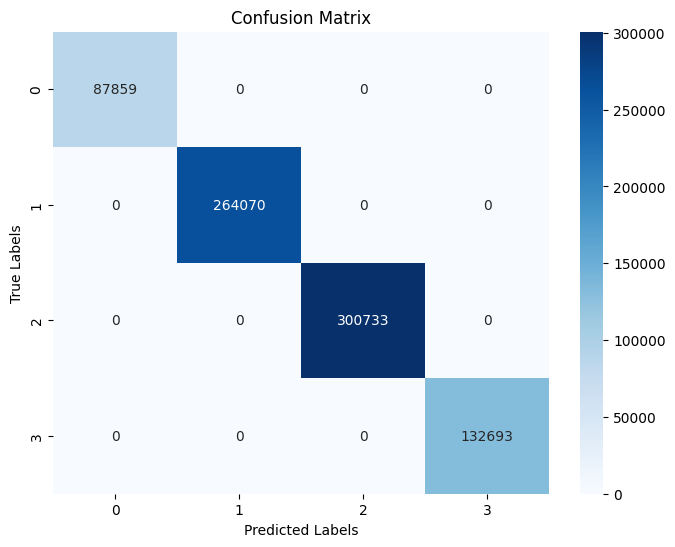

In [6]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/updated_models/1st_round_felids_rnn_cate_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/category/client3_FELIDS_rnn_cate_1st_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [7]:
print(f"Accuracy for 4 class classification felids_rnn_cate_1st fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_rnn_cate_1st  fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_rnn_cate_1st  fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_rnn_cate_1st  fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_rnn_cate_1st  fl: {mcc:.4f}")

Accuracy for 4 class classification felids_rnn_cate_1st fl: 1.0000
Precision for 4 class classification felids_rnn_cate_1st  fl: 1.0000
Recall for 4 class classification felids_rnn_cate_1st  fl: 1.0000
F1 Score for 4 class classification felids_rnn_cate_1st  fl: 1.0000
MCC for 4 class classification felids_rnn_cate_1st  fl: 1.0000


In [11]:
y1.unique()

array([1, 4, 3, 2, 0])

FELIDS  rnn type classification before FL

45812/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.9383 - loss: 0.1749
Epoch 1: val_loss improved from inf to 5.01469, saving model to D:/linthoi/FL_models/new/client3/type/client3_FELIDS_rnn_type_bfore_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 2700s 59ms/step - accuracy: 0.9383 - loss: 0.1749 - val_accuracy: 0.5131 - val_loss: 5.0147
Restoring model weights from the end of the best epoch: 1.
24543/24543 ━━━━━━━━━━━━━━━━━━━━ 430s 17ms/step
Accuracy Score: 0.5130902585454985


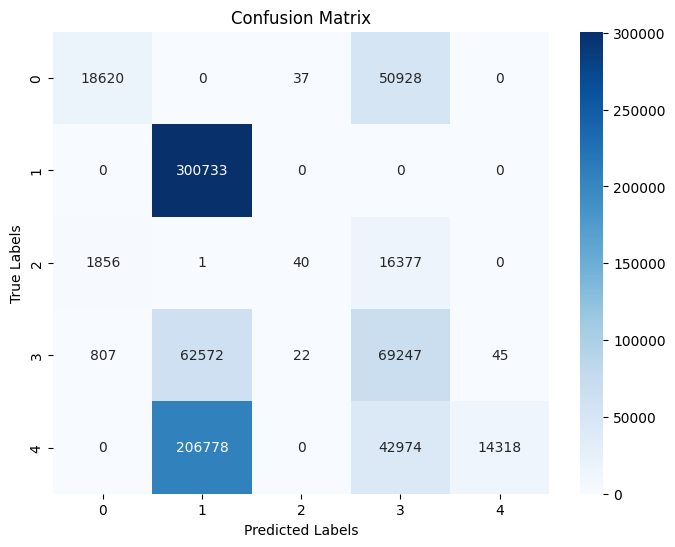

In [9]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/firstinitialized/felids_RNN_type.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/type/client3_FELIDS_rnn_type_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [10]:
print(f"Accuracy for 5 class classification felids_rnn_type_bfore fl: {accuracy:.4f}")
print(f"Precision for 5 class classification felids_rnn_type_bfore  fl: {precision:.4f}")
print(f"Recall for 5 class classification felids_rnn_type_bfore  fl: {recall:.4f}")
print(f"F1 Score for 5 class classification felids_rnn_type_bfore  fl: {f1:.4f}")
print(f"MCC for 5 class classification felids_rnn_type_bfore  fl: {mcc:.4f}")

Accuracy for 5 class classification felids_rnn_type_bfore fl: 0.5131
Precision for 5 class classification felids_rnn_type_bfore  fl: 0.6378
Recall for 5 class classification felids_rnn_type_bfore  fl: 0.3692
F1 Score for 5 class classification felids_rnn_type_bfore  fl: 0.3303
MCC for 5 class classification felids_rnn_type_bfore  fl: 0.3459


1st fl round felids type classification

45812/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.9395 - loss: 0.1632
Epoch 1: val_loss improved from inf to 0.03607, saving model to D:/linthoi/FL_models/new/client3/type/client3_FELIDS_rnn_type_1st_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 3060s 67ms/step - accuracy: 0.9395 - loss: 0.1632 - val_accuracy: 0.9906 - val_loss: 0.0361
Restoring model weights from the end of the best epoch: 1.
24543/24543 ━━━━━━━━━━━━━━━━━━━━ 473s 19ms/step
Accuracy Score: 0.990417072534077


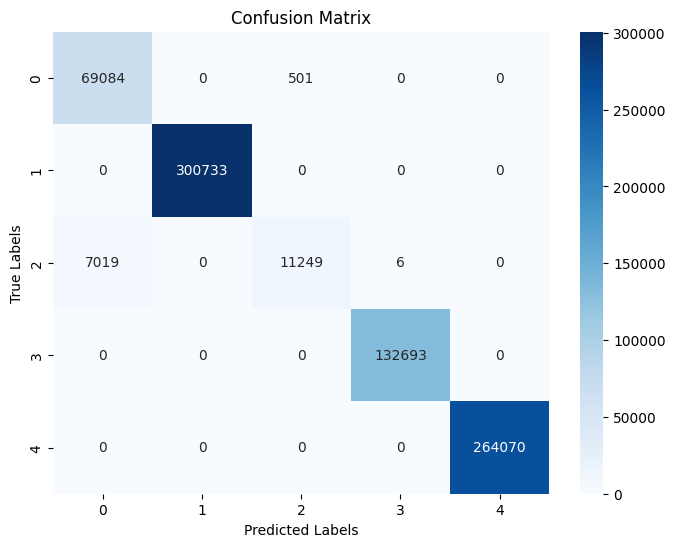

In [6]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/1st_round_felids_rnn_type_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/type/client3_FELIDS_rnn_type_1st_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [7]:
print(f"Accuracy for 5 class classification felids_rnn_type_1st fl: {accuracy:.4f}")
print(f"Precision for 5 class classification felids_rnn_type_1st  fl: {precision:.4f}")
print(f"Recall for 5 class classification felids_rnn_type_1st  fl: {recall:.4f}")
print(f"F1 Score for 5 class classification felids_rnn_type_1st  fl: {f1:.4f}")
print(f"MCC for 5 class classification felids_rnn_type_1st  fl: {mcc:.4f}")

Accuracy for 5 class classification felids_rnn_type_1st fl: 0.9904
Precision for 5 class classification felids_rnn_type_1st  fl: 0.9730
Recall for 5 class classification felids_rnn_type_1st  fl: 0.9217
F1 Score for 5 class classification felids_rnn_type_1st  fl: 0.9395
MCC for 5 class classification felids_rnn_type_1st  fl: 0.9865


felids rnn type 2nd fl round

45813/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - accuracy: 0.9279 - loss: 0.1718
Epoch 1: val_loss improved from inf to 0.05681, saving model to D:/linthoi/FL_models/new/client3/type/client3_FELIDS_rnn_type_2nd_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 5053s 110ms/step - accuracy: 0.9279 - loss: 0.1718 - val_accuracy: 0.9767 - val_loss: 0.0568
Restoring model weights from the end of the best epoch: 1.
24543/24543 ━━━━━━━━━━━━━━━━━━━━ 572s 23ms/step
Accuracy Score: 0.9767289951677903


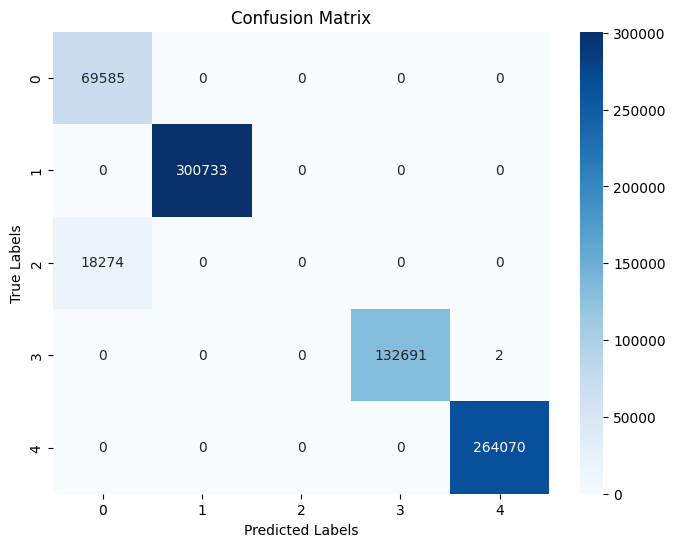

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [8]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/2nd_round_felids_rnn_type_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/type/client3_FELIDS_rnn_type_2nd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [9]:
print(f"Accuracy for 5 class classification felids_rnn_type_2nd fl: {accuracy:.4f}")
print(f"Precision for 5 class classification felids_rnn_type_2nd  fl: {precision:.4f}")
print(f"Recall for 5 class classification felids_rnn_type_2nd  fl: {recall:.4f}")
print(f"F1 Score for 5 class classification felids_rnn_type_2nd  fl: {f1:.4f}")
print(f"MCC for 5 class classification felids_rnn_type_2nd  fl: {mcc:.4f}")

Accuracy for 5 class classification felids_rnn_type_2nd fl: 0.9767
Precision for 5 class classification felids_rnn_type_2nd  fl: 0.7584
Recall for 5 class classification felids_rnn_type_2nd  fl: 0.8000
F1 Score for 5 class classification felids_rnn_type_2nd  fl: 0.7768
MCC for 5 class classification felids_rnn_type_2nd  fl: 0.9676


3rd felids rnn type classification fl round

45813/45813 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.9719 - loss: 0.0766
Epoch 1: val_loss improved from inf to 0.05706, saving model to D:/linthoi/FL_models/new/client3/type/client3_FELIDS_rnn_type_3rd_FL_weight.keras
45813/45813 ━━━━━━━━━━━━━━━━━━━━ 3263s 71ms/step - accuracy: 0.9719 - loss: 0.0766 - val_accuracy: 0.9767 - val_loss: 0.0571
Restoring model weights from the end of the best epoch: 1.
24543/24543 ━━━━━━━━━━━━━━━━━━━━ 472s 19ms/step
Accuracy Score: 0.9767315417868353


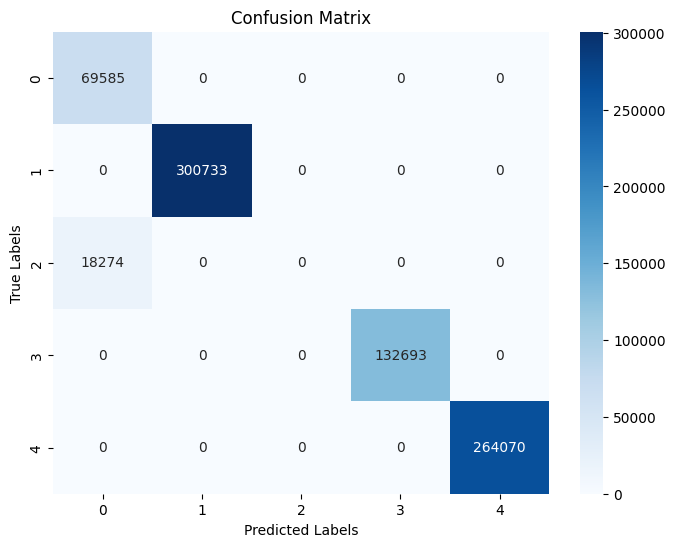

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [6]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/3rd_round_felids_rnn_type_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client3/type/client3_FELIDS_rnn_type_3rd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [7]:
print(f"Accuracy for 5 class classification felids_rnn_type_3rd fl: {accuracy:.4f}")
print(f"Precision for 5 class classification felids_rnn_type_3rd  fl: {precision:.4f}")
print(f"Recall for 5 class classification felids_rnn_type_3rd  fl: {recall:.4f}")
print(f"F1 Score for 5 class classification felids_rnn_type_3rd  fl: {f1:.4f}")
print(f"MCC for 5 class classification felids_rnn_type_3rd  fl: {mcc:.4f}")

Accuracy for 5 class classification felids_rnn_type_3rd fl: 0.9767
Precision for 5 class classification felids_rnn_type_3rd  fl: 0.7584
Recall for 5 class classification felids_rnn_type_3rd  fl: 0.8000
F1 Score for 5 class classification felids_rnn_type_3rd  fl: 0.7768
MCC for 5 class classification felids_rnn_type_3rd  fl: 0.9676
